# Analysis of architecture-conditioned factual-error repair

In [ ]:
from pathlib import Path
import os, json, itertools, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, rankdata, spearmanr
from IPython.display import display, Markdown

BASE = Path(os.environ.get("ARR_ANALYSIS_BASE", "********"))
OUTPUT_DIR = Path(os.environ.get("ARR_ANALYSIS_OUTPUT", "analysis_outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42
N_BOOT = 5000
N_PERM = 19999
ALPHA = 0.05
TASK_ORDER = ["Public Narrative Synthesis", "Project Ideation", "Related Work"]
MODEL_ORDER = ["Gemma3", "Qwen3", "DeepSeek-R1"]
CONFIG_ORDER = ["Direct", "Decomposed", "Direct+HDM", "Decomposed+HDM"]
WORKFLOW_ORDER = ["Direct+HDM", "Decomposed+HDM"]
TASK_SIZES = {"Public Narrative Synthesis": 55, "Project Ideation": 100, "Related Work": 100}
TEMPERATURES = [0.0, 0.5, 1.0]
RUN_IDS = [1, 2, 3]
MATCH_KEYS = ["task", "model_label", "instance_id", "generation_temperature_unified", "run_id"]
SOURCE_KEYS = ["task", "instance_id"]
COLORS = {"Direct+HDM": "#3B6FB6", "Decomposed+HDM": "#D9792B"}
TASK_SHORT = {"Public Narrative Synthesis": "PNS", "Project Ideation": "PRI", "Related Work": "RWG"}
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)
plt.rcParams.update({"pdf.fonttype": 42, "font.size": 9})
TABLES = {}

def show_table(name, df):
    TABLES[name] = df.copy()
    display(df)
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

def save_figure(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Input project:", BASE)
print("Output directory:", OUTPUT_DIR.resolve())

## 1. Inputs and matching integrity

In [2]:
# ============================================================
# 1. Data file registry
# ============================================================

DATA_SPECS = [
    # ---------------- Public Narrative Synthesis ----------------
    dict(task="Public Narrative Synthesis", config="Direct", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline1_SingleAgent+Judge_pns/Baseline1_SingleAgent+Judge_pns_gemma3/baseline1_pns_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Direct", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline1_SingleAgent+Judge_pns/Baseline1_SingleAgent+Judge_pns_qwen3/baseline1_pns_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Direct", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline1_SingleAgent+Judge_pns/Baseline1_SingleAgent+Judge_pns_deepseekr1/baseline1_pns_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Public Narrative Synthesis", config="Decomposed", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline2_MultiAgent+Judge_pns/Baseline2_MultiAgent+Judge_pns_gemma3/multi_agent_pns_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Decomposed", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline2_MultiAgent+Judge_pns/Baseline2_MultiAgent+Judge_pns_qwen3/multi_agent_pns_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Decomposed", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/Baseline2_MultiAgent+Judge_pns/Baseline2_MultiAgent+Judge_pns_deepseekr1/multi_agent_pns_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Public Narrative Synthesis", config="Direct+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/SingleAgent+HDM_pns/SingleAgent+HDM_pns_gemma3/singleagent_hdm_pns_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Direct+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/SingleAgent+HDM_pns/SingleAgent+HDM_pns_qwen3/singleagent_hdm_pns_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Direct+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/SingleAgent+HDM_pns/SingleAgent+HDM_pns_deepseekr1/singleagent_hdm_pns_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Public Narrative Synthesis", config="Decomposed+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/MultiAgent+HDM_pns/MultiAgent+HDM_pns_gemma3/multiagent_hdm_pns_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Decomposed+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/MultiAgent+HDM_pns/MultiAgent+HDM_pns_qwen3/multiagent_hdm_pns_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Public Narrative Synthesis", config="Decomposed+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/public_event_narrative_synthesis_ARR/MultiAgent+HDM_pns/MultiAgent+HDM_pns_deepseekr1/multiagent_hdm_pns_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    # ---------------- Related Work ----------------
    dict(task="Related Work", config="Direct", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline1_SingleAgent+Judge/Baseline1_rw_gemma3latest/baseline1_rw_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Direct", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline1_SingleAgent+Judge/Baseline1_rw_qwen3/baseline1_rw_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Direct", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline1_SingleAgent+Judge/Baseline1_rw_deepseekr1/baseline1_rw_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Related Work", config="Decomposed", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline2_MultiAgent+Judge/Baseline2_rw_gemma3latest/multi_agent_related_work_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Decomposed", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline2_MultiAgent+Judge/Baseline2_rw_qwen3/multi_agent_related_work_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Decomposed", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/Baseline2_MultiAgent+Judge/Baseline2_rw_deepseekr1/multi_agent_related_work_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Related Work", config="Direct+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/SingleAgent+HDM_rw_arr/SingleAgent+HDM_rw_arr_gemma3/singleagent_hdm_rw_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Direct+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/SingleAgent+HDM_rw_arr/SingleAgent+HDM_rw_arr_qwen3/singleagent_hdm_rw_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Direct+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/SingleAgent+HDM_rw_arr/SingleAgent+HDM_rw_arr_deepseekr1/singleagent_hdm_rw_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Related Work", config="Decomposed+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/MultiAgent+HDM_rw_arr/MultiAgent+HDM_rw_arr_gemma3/multi_agent_hdm_rw_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Decomposed+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/MultiAgent+HDM_rw_arr/MultiAgent+HDM_rw_arr_qwen3/multi_agent_hdm_rw_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Related Work", config="Decomposed+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/related_work_ARR/MultiAgent+HDM_rw_arr/MultiAgent+HDM_rw_arr_deepseekr1/multi_agent_hdm_rw_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    # ---------------- Project-Grounded Research Ideation ----------------
    dict(task="Project Ideation", config="Direct", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline1_SingleAgent+Judge/Baseline1_SingleAgent+Judge_gemma3/baseline1_grant_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Direct", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline1_SingleAgent+Judge/Baseline1_SingleAgent+Judge_qwen3/baseline1_grant_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Direct", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline1_SingleAgent+Judge/Baseline1_SingleAgent+Judge_deepseekr1/baseline1_grant_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Project Ideation", config="Decomposed", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline2_MultiAgent+Judge/Baseline2_MultiAgent+Judge_gemma3/multi_agent_grant_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Decomposed", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline2_MultiAgent+Judge/Baseline2_MultiAgent+Judge_qwen3/multi_agent_grant_qwen3_baseline2_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Decomposed", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/Baseline2_MultiAgent+Judge/Baseline2_MultiAgent+Judge_deepseekr1/multi_agent_grant_deepseekr1_baseline2_all_temperatures_combined_with_rerun.csv"),

    dict(task="Project Ideation", config="Direct+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/SingleAgent+HDM_grant_arr/SingleAgent+HDM_grant_arr_gemma3/singleAgent_HDM_grant_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Direct+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/SingleAgent+HDM_grant_arr/SingleAgent+HDM_grant_arr_qwen3/singleAgent_HDM_grant_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Direct+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/SingleAgent+HDM_grant_arr/SingleAgent+HDM_grant_arr_deepseekr1/singleAgent_HDM_grant_deepseekr1_all_temperatures_combined_with_rerun.csv"),

    dict(task="Project Ideation", config="Decomposed+HDM", model_label="Gemma3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/MultiAgent+HDM_grant_arr/MultiAgent+HDM_grant_arr_gemma3/multiAgent_HDM_grant_gemma3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Decomposed+HDM", model_label="Qwen3",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/MultiAgent+HDM_grant_arr/MultiAgent+HDM_grant_arr_qwen3/multiAgent_HDM_grant_qwen3_all_temperatures_combined_with_rerun.csv"),
    dict(task="Project Ideation", config="Decomposed+HDM", model_label="DeepSeek-R1",
         path=BASE/"CSVs_after_runs/ARR/grant_research_ideation/MultiAgent+HDM_grant_arr/MultiAgent+HDM_grant_arr_deepseekr1/multiAgent_HDM_grant_deepseekr1_all_temperatures_combined_with_rerun.csv"),
]

assert len(DATA_SPECS) == 36

In [ ]:
def is_missing(v):
    if v is None: return True
    if isinstance(v, (dict, list, tuple)): return False
    try: return bool(pd.isna(v))
    except (ValueError, TypeError): return False

def parse_json(v, expected=None):
    if is_missing(v): return None
    if isinstance(v, (dict, list)): obj = v
    else:
        try: obj = json.loads(str(v))
        except (ValueError, TypeError): return None
    return obj if expected is None or isinstance(obj, expected) else None

def first_nonempty(row, names):
    for name in names:
        v = row.get(name)
        if not is_missing(v) and str(v).strip().lower() not in ("", "none", "nan"):
            return str(v).strip()
    return ""

def normalize_id(v):
    s = str(v).strip()
    # Normalize integral CSV IDs (e.g. 8.0 and 8) without converting arbitrary strings.
    if s.endswith(".0") and s[:-2].lstrip("-").isdigit(): return s[:-2]
    return s

def make_instance_id(row):
    rid = first_nonempty(row, ["row_id"])
    if rid: return normalize_id(rid)
    task = row["task"]
    if task == "Public Narrative Synthesis":
        vals = [first_nonempty(row, [x]) for x in ["year", "month", "date", "event"]]
        return "|".join(vals) if all(vals) else ""
    if task == "Project Ideation": return normalize_id(first_nonempty(row, ["grant_id", "project_url", "title"]))
    aid, mid = first_nonempty(row, ["aid"]), first_nonempty(row, ["mid"])
    return f"{aid}|{mid}" if aid or mid else first_nonempty(row, ["query_abstract"])

manifest_rows, frames = [], []
for spec in DATA_SPECS:
    if not Path(spec["path"]).is_file(): raise FileNotFoundError(spec["path"])
    raw = pd.read_csv(spec["path"])
    if "run_status" in raw:
        status = raw["run_status"].astype(str).str.strip().str.lower()
        keep = status.eq("successful")
    else:
        status = pd.Series("not_recorded", index=raw.index)
        keep = pd.Series(True, index=raw.index)
        warnings.warn(f"run_status unavailable: {spec['path']}; all CSV rows retained, then audited")
    df = raw.loc[keep].copy()
    df["input_csv_row"] = df.index + 2
    for c in ["task", "config", "model_label"]: df[c] = spec[c]
    df["source_file"] = str(spec["path"])
    df["instance_id"] = df.apply(make_instance_id, axis=1)
    temps = ["generation_temperature", "writer_temperature", "planner_temperature", "executor_temperature", "synthesizer_temperature"]
    temperature = pd.Series(np.nan, index=df.index)
    for c in temps:
        if c in df:
            vals = pd.to_numeric(df[c], errors="coerce")
            conflict = temperature.notna() & vals.notna() & ~np.isclose(temperature, vals, equal_nan=True)
            if conflict.any(): raise ValueError(f"Generation stage temperature conflict: {spec['path']}")
            temperature = temperature.fillna(vals)
    df["generation_temperature_unified"] = temperature
    if "run_id" not in df: raise ValueError(f"Missing repetition identifier: {spec['path']}")
    df["run_id"] = pd.to_numeric(df["run_id"], errors="coerce")
    df["architecture"] = np.where(df["config"].isin(["Direct", "Direct+HDM"]), "Direct", "Decomposed")
    frames.append(df)
    manifest_rows.append({**{k: spec[k] for k in ["task", "config", "model_label"]},
                          "csv_rows": len(raw), "retained_rows": len(df), "excluded_status_rows": int((~keep).sum()),
                          "status_counts": json.dumps(status.value_counts().to_dict()), "path": str(spec["path"])})
all_df = pd.concat(frames, ignore_index=True, sort=False)
all_df["record_id"] = np.arange(len(all_df))
manifest = pd.DataFrame(manifest_rows)
show_table("input_manifest", manifest)
bad_keys = all_df[MATCH_KEYS].isna().any(axis=1) | all_df["instance_id"].eq("")
bad_keys |= ~all_df["generation_temperature_unified"].isin(TEMPERATURES) | ~all_df["run_id"].isin(RUN_IDS)
duplicates = all_df.duplicated(MATCH_KEYS + ["config"], keep=False)
show_table("matching_key_issues", all_df.loc[bad_keys | duplicates, MATCH_KEYS + ["config", "source_file", "input_csv_row"]])
if bad_keys.any() or duplicates.any(): raise ValueError("Invalid or duplicate matching keys; inspect matching_key_issues.csv before analysis")
# Cross-configuration IDs must refer to the same source, not merely share a row number.
identity_issues=[]
for field in ["event", "grant_id", "aid", "mid"]:
    if field not in all_df: continue
    x=all_df[SOURCE_KEYS+[field]].dropna(subset=[field]).copy()
    x[field]=x[field].map(normalize_id)
    x=x[~x[field].isin(["", "None", "nan"])]
    variations=x.groupby(SOURCE_KEYS)[field].nunique()
    for (task,instance),count in variations[variations>1].items():
        identity_issues.append({"task":task,"instance_id":instance,"field":field,"distinct_values":int(count)})
show_table("source_identity_conflicts",pd.DataFrame(identity_issues,columns=SOURCE_KEYS+["field","distinct_values"]))
if identity_issues:raise ValueError("The same matching ID refers to conflicting source metadata; inspect source_identity_conflicts.csv")
coverage = all_df.groupby(["task", "config", "model_label"], as_index=False).agg(
    successful_rows=("instance_id", "size"), unique_sources=("instance_id", "nunique"))
coverage["planned_rows"] = coverage["task"].map(TASK_SIZES) * len(TEMPERATURES) * len(RUN_IDS)
coverage["missing_planned_rows"] = coverage["planned_rows"] - coverage["successful_rows"]
coverage["completion_fraction"] = coverage["successful_rows"] / coverage["planned_rows"]
show_table("successful_run_coverage", coverage)
setting_coverage = all_df.groupby(["task", "config", "model_label", "generation_temperature_unified", "run_id"], as_index=False).size()
show_table("coverage_by_setting", setting_coverage)
planned_runs = sum(TASK_SIZES.values()) * 4 * 3 * 3 * 3
print(f"Planned: {planned_runs:,}; retained: {len(all_df):,}; absent or unsuccessful: {planned_runs-len(all_df):,}")
print("Inference is conditional on successful, valid records; failure rates remain part of the coverage report.")

## 2. Audit factuality and final-quality records

In [4]:
def finite_number(v):
    if isinstance(v, (bool, np.bool_)): return np.nan
    try:
        x = float(v)
        return x if np.isfinite(x) else np.nan
    except (ValueError, TypeError): return np.nan

def strict_bool(v):
    if isinstance(v, (bool, np.bool_)): return bool(v)
    if str(v).strip().lower() in ("true", "1", "1.0"): return True
    if str(v).strip().lower() in ("false", "0", "0.0"): return False
    return None

def audit_hdm(value):
    h = parse_json(value, dict)
    result = {"valid": False, "reason": "malformed_hdm_json", "wrong": np.nan, "total": np.nan, "rate": np.nan}
    if h is None: return result
    claims, verifications = h.get("extracted_claims"), h.get("claim_verifications")
    if not isinstance(claims, list) or not isinstance(verifications, list):
        result["reason"] = "missing_claim_or_verification_list"; return result
    def ids(items):
        if not all(isinstance(c, dict) and c.get("claim_id") is not None and str(c["claim_id"]).strip() for c in items): return None
        return [str(c["claim_id"]).strip() for c in items]
    cid, vid = ids(claims), ids(verifications)
    if cid is None or vid is None or len(set(cid)) != len(cid) or len(set(vid)) != len(vid) or set(cid) != set(vid):
        result["reason"] = "duplicate_missing_or_unexpected_claim_ids"; return result
    if not cid: result["reason"] = "empty_claim_extraction"; return result
    labels = [str(c.get("label", "")).strip().lower() for c in verifications]
    if not set(labels).issubset({"supported", "unsupported", "contradicted"}):
        result["reason"] = "invalid_verification_labels"; return result
    wrong = [c for c, lab in zip(verifications, labels) if lab != "supported"]
    stored_wrong = h.get("wrong_claims")
    # Full verification array is authoritative; wrong_claims must describe the same ID set.
    if not isinstance(stored_wrong, list) or ids(stored_wrong) is None or len(ids(stored_wrong)) != len(set(ids(stored_wrong))) or set(ids(stored_wrong)) != {str(c['claim_id']).strip() for c in wrong}:
        result["reason"] = "wrong_claim_list_disagrees_with_verifications"; return result
    result.update(valid=True, reason="valid", wrong=len(wrong), total=len(claims), rate=len(wrong)/len(claims), hdm=h)
    return result

repair_raw = all_df[all_df["config"].isin(WORKFLOW_ORDER)].copy()
hdm_audit_rows = []
for _, row in repair_raw.iterrows():
    for stage, suffix in [("pre", "before"), ("post", "after")]:
        a = audit_hdm(row.get(f"hdm_{suffix}_json"))
        corrected = []
        if a["valid"]:
            for field, val in [(f"hdm_wrong_claim_count_{suffix}", a["wrong"]), (f"hdm_total_claims_{suffix}", a["total"]), (f"hdm_hallucination_rate_{suffix}", a["rate"])]:
                stored = finite_number(row.get(field))
                if not np.isfinite(stored) or not np.isclose(stored, val, atol=1e-8): corrected.append(field)
        hdm_audit_rows.append({"record_id": row["record_id"], "stage": stage, **{k:a[k] for k in ["valid","reason","wrong","total","rate"]}, "corrected_scalar_fields": ";".join(corrected)})
hdm_audit = pd.DataFrame(hdm_audit_rows)
show_table("hdm_audit", hdm_audit.merge(all_df[["record_id"]+MATCH_KEYS+["config"]], on="record_id", validate="many_to_one"))
show_table("hdm_audit_summary", hdm_audit.groupby(["stage","valid","reason"], as_index=False).size())
for stage, label in [("pre", "before"), ("post", "after")]:
    a = hdm_audit[hdm_audit.stage.eq(stage)].set_index("record_id")
    repair_raw[f"{stage}_valid"] = repair_raw.record_id.map(a.valid)
    for metric, col in [("wrong", f"wrong_{label}"), ("total", f"claims_{label}"), ("rate", f"hall_rate_{label}")]:
        repair_raw[col] = repair_raw.record_id.map(a[metric])
repair_raw["initial_error"] = np.where(repair_raw.pre_valid, (repair_raw.wrong_before > 0).astype(float), np.nan)
repair_df = repair_raw[repair_raw.pre_valid & repair_raw.post_valid].copy()
repair_df["repair_eligible"] = repair_df.wrong_before.gt(0)
repair_df["wrong_claim_reduction"] = repair_df.wrong_before - repair_df.wrong_after
repair_df["repairability_count"] = (repair_df.wrong_claim_reduction / repair_df.wrong_before).where(repair_df.repair_eligible)
repair_df["complete_repair"] = repair_df.wrong_after.eq(0).astype(float).where(repair_df.repair_eligible)
repair_df["hall_rate_reduction_abs"] = repair_df.hall_rate_before - repair_df.hall_rate_after
repair_df["hall_rate_reduction_rel"] = (repair_df.hall_rate_reduction_abs / repair_df.hall_rate_before).where(repair_df.repair_eligible)
repair_df["claim_count_change"] = repair_df.claims_after - repair_df.claims_before
repair_df["repair_outcome"] = np.select(
    [~repair_df.repair_eligible, repair_df.wrong_after.eq(0), repair_df.wrong_after.lt(repair_df.wrong_before), repair_df.wrong_after.eq(repair_df.wrong_before)],
    ["no_initial_error", "complete", "partial", "unchanged"], default="worsened")
eligible = repair_df[repair_df.repair_eligible].copy()

# Audit normalized quality scores from complete judge JSON where available.
QUALITY_NAMES = {
    "Public Narrative Synthesis": ["core_event_fidelity","required_entity_coverage","key_information_coverage","cross_source_synthesis","structural_coverage","statistics_and_claims_accuracy","narrative_quality"],
    "Project Ideation": ["source_relevance","novelty","feasibility","specificity","structure","metadata_grounding","writing_quality"],
    "Related Work": ["source_grounding","citation_faithfulness","reference_coverage","synthesis_quality","organization","specificity","writing_quality"],
}
COMM_NAMES = ["coherence", "readability", "conciseness"]
quality_rows = []
for _, row in all_df.iterrows():
    j = parse_json(row.get("judge_output_json"), dict)
    out = {"record_id": row.record_id}
    for metric, scalar, part, names in [
        ("TQS", "total_dimension_score", "dimension_scores", QUALITY_NAMES[row.task]),
        ("CQS", "total_quality_analysis_score", "quality_analysis", COMM_NAMES)]:
        raw = finite_number(row.get(scalar)); reason = "validated_scalar_only"
        values = None
        if j is not None:
            block = j.get(part)
            # Actual JSON rubric fields are recorded and compared across configurations.
            # Require all seven task dimensions / all three communication dimensions.
            observed_names=sorted(block) if isinstance(block,dict) else []
            out[f"{metric}_schema"]=json.dumps(observed_names)
            values = [finite_number(block[x]) for x in observed_names] if isinstance(block, dict) else []
            if len(values) != len(names) or not all(np.isfinite(v) and 0 <= v <= 1 for v in values):
                value = np.nan; reason = "invalid_or_missing_judge_subscores"
            else:
                value = float(np.mean(values))
                reason = "json_recomputed" if not np.isfinite(raw) or not np.isclose(raw, value, atol=1e-8) else "json_validated"
        else:
            out[f"{metric}_schema"]="not_recorded"
            if not is_missing(row.get("judge_output_json")):
                value=np.nan;reason="malformed_judge_json"
            else:
                value = raw if np.isfinite(raw) and 0 <= raw <= 1 else np.nan
                if not np.isfinite(value): reason = "invalid_or_missing_scalar"
        out[metric] = value; out[f"{metric}_audit"] = reason
    runtime = finite_number(row.get("total_elapsed_sec"))
    out["total_runtime_sec"] = runtime if runtime >= 0 else np.nan
    quality_rows.append(out)
quality_audit = pd.DataFrame(quality_rows)
show_table("quality_audit", quality_audit.merge(all_df[["record_id"]+MATCH_KEYS+["config"]], on="record_id", validate="one_to_one"))
schema_records=quality_audit.merge(all_df[["record_id","task","config"]],on="record_id",validate="one_to_one")
for metric in ["TQS","CQS"]:
    schema_table=schema_records.groupby(["task","config",f"{metric}_schema",f"{metric}_audit"],dropna=False,as_index=False).size()
    show_table(f"quality_rubric_schema_{metric}",schema_table)
    valid=schema_records[schema_records[metric].notna()&schema_records[f"{metric}_schema"].ne("not_recorded")]
    variants=valid.groupby("task")[f"{metric}_schema"].nunique()
    if (variants>1).any():
        raise ValueError(f"{metric} uses different rubric field sets within a task. Inspect quality_rubric_schema_{metric}.csv; comparable rubric scores cannot be assumed.")
all_df = all_df.merge(quality_audit, on="record_id", validate="one_to_one")
for name in ["repair_raw", "repair_df", "eligible"]:
    globals()[name] = globals()[name].merge(quality_audit, on="record_id", validate="one_to_one")
print("Valid pre passes:", int(repair_raw.pre_valid.sum()), "valid recovery outputs:", len(repair_df), "eligible valid recovery outputs:", len(eligible))

,record_id,stage,valid,reason,wrong,total,rate,corrected_scalar_fields,task,model_label,instance_id,generation_temperature_unified,run_id,config
0,2888,pre,True,valid,0.0,13.0,0.000000,,Public Narrative Synthesis,Gemma3,2,0.0,1,Direct+HDM
1,2888,post,True,valid,0.0,13.0,0.000000,,Public Narrative Synthesis,Gemma3,2,0.0,1,Direct+HDM
2,2889,pre,True,valid,0.0,16.0,0.000000,,Public Narrative Synthesis,Gemma3,3,0.0,1,Direct+HDM
3,2889,post,True,valid,0.0,16.0,0.000000,,Public Narrative Synthesis,Gemma3,3,0.0,1,Direct+HDM
4,2890,pre,True,valid,0.0,14.0,0.000000,,Public Narrative Synthesis,Gemma3,4,0.0,1,Direct+HDM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26967,26959,post,True,valid,3.0,18.0,0.166667,,Project Ideation,DeepSeek-R1,2545538,1.0,3,Decomposed+HDM
26968,26960,pre,True,valid,0.0,15.0,0.000000,,Project Ideation,DeepSeek-R1,2531941,1.0,3,Decomposed+HDM
26969,26960,post,True,valid,0.0,15.0,0.000000,,Project Ideation,DeepSeek-R1,2531941,1.0,3,Decomposed+HDM
26970,26961,pre,True,valid,13.0,18.0,0.722222,,Project Ideation,DeepSeek-R1,2513540,1.0,3,Decomposed+HDM


,stage,valid,reason,size
0,post,False,duplicate_missing_or_unexpected_claim_ids,55
1,post,True,valid,13431
2,pre,False,duplicate_missing_or_unexpected_claim_ids,54
3,pre,True,valid,13432


,record_id,TQS_schema,TQS,TQS_audit,CQS_schema,CQS,CQS_audit,total_runtime_sec,task,model_label,instance_id,generation_temperature_unified,run_id,config
0,0,"[""core_event_fidelity"", ""cross_source_synthesi...",0.857143,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.816667,json_validated,13.618,Public Narrative Synthesis,Gemma3,3,0.0,1,Direct
1,1,"[""core_event_fidelity"", ""cross_source_synthesi...",0.842857,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.800000,json_validated,13.008,Public Narrative Synthesis,Gemma3,5,0.0,1,Direct
2,2,"[""core_event_fidelity"", ""cross_source_synthesi...",0.924286,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.916667,json_validated,17.795,Public Narrative Synthesis,Gemma3,6,0.0,1,Direct
3,3,"[""core_event_fidelity"", ""cross_source_synthesi...",0.871429,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.866667,json_validated,17.863,Public Narrative Synthesis,Gemma3,7,0.0,1,Direct
4,4,"[""core_event_fidelity"", ""cross_source_synthesi...",0.878571,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.816667,json_validated,13.875,Public Narrative Synthesis,Gemma3,8,0.0,1,Direct
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26957,26957,"[""feasibility"", ""metadata_grounding"", ""novelty...",0.900000,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.900000,json_validated,579.796,Project Ideation,DeepSeek-R1,2603392,1.0,3,Decomposed+HDM
26958,26958,"[""feasibility"", ""metadata_grounding"", ""novelty...",0.907143,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.883333,json_validated,519.705,Project Ideation,DeepSeek-R1,2525849,1.0,3,Decomposed+HDM
26959,26959,"[""feasibility"", ""metadata_grounding"", ""novelty...",0.907143,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.900000,json_validated,561.473,Project Ideation,DeepSeek-R1,2545538,1.0,3,Decomposed+HDM
26960,26960,"[""feasibility"", ""metadata_grounding"", ""novelty...",0.907143,json_validated,"[""coherence"", ""conciseness"", ""readability""]",0.883333,json_validated,382.313,Project Ideation,DeepSeek-R1,2531941,1.0,3,Decomposed+HDM


,task,config,TQS_schema,TQS_audit,size
0,Project Ideation,Decomposed,"[""feasibility"", ""metadata_grounding"", ""novelty...",json_validated,2673
1,Project Ideation,Decomposed+HDM,"[""feasibility"", ""metadata_grounding"", ""novelty...",json_validated,2631
2,Project Ideation,Direct,"[""feasibility"", ""metadata_grounding"", ""novelty...",json_validated,2575
3,Project Ideation,Direct+HDM,"[""feasibility"", ""metadata_grounding"", ""novelty...",json_validated,2649
4,Public Narrative Synthesis,Decomposed,"[""core_event_fidelity"", ""cross_source_synthesi...",json_validated,1476
5,Public Narrative Synthesis,Decomposed+HDM,"[""core_event_fidelity"", ""cross_source_synthesi...",json_validated,1460
6,Public Narrative Synthesis,Direct,"[""core_event_fidelity"", ""cross_source_synthesi...",json_validated,1412
7,Public Narrative Synthesis,Direct+HDM,"[""core_event_fidelity"", ""cross_source_synthesi...",json_validated,1407
8,Related Work,Decomposed,"[""citation_faithfulness"", ""organization"", ""ref...",json_validated,2678
9,Related Work,Decomposed+HDM,"[""citation_faithfulness"", ""organization"", ""ref...",json_validated,2655


,task,config,CQS_schema,CQS_audit,size
0,Project Ideation,Decomposed,"[""coherence"", ""conciseness"", ""readability""]",json_validated,2673
1,Project Ideation,Decomposed+HDM,"[""coherence"", ""conciseness"", ""readability""]",json_validated,2631
2,Project Ideation,Direct,"[""coherence"", ""conciseness"", ""readability""]",invalid_or_missing_judge_subscores,1
3,Project Ideation,Direct,"[""coherence"", ""conciseness"", ""readability""]",json_validated,2574
4,Project Ideation,Direct+HDM,"[""coherence"", ""conciseness"", ""readability""]",json_validated,2649
5,Public Narrative Synthesis,Decomposed,"[""coherence"", ""conciseness"", ""readability""]",json_validated,1476
6,Public Narrative Synthesis,Decomposed+HDM,"[""coherence"", ""conciseness"", ""readability""]",json_validated,1460
7,Public Narrative Synthesis,Direct,"[""coherence"", ""conciseness"", ""readability""]",json_validated,1412
8,Public Narrative Synthesis,Direct+HDM,"[""coherence"", ""conciseness"", ""readability""]",json_validated,1407
9,Related Work,Decomposed,"[""coherence"", ""conciseness"", ""readability""]",json_validated,2678


Valid pre passes: 13432 valid recovery outputs: 13408 eligible valid recovery outputs: 4147


## 3. Shared estimation, uncertainty, and multiplicity

In [5]:
def rng_for(label):
    digest = int.from_bytes(hashlib.sha256(str(label).encode()).digest()[:4], "little")
    return np.random.default_rng((RANDOM_SEED + digest) % (2**32))

def bootstrap_source_mean(values, label="mean"):
    x = np.asarray(values, dtype=float); x = x[np.isfinite(x)]
    if len(x) < 2: return (np.nan, np.nan)
    rng = rng_for((label, "bootstrap")); draws = []
    for start in range(0, N_BOOT, 250):
        b = min(250, N_BOOT-start)
        draws.extend(x[rng.integers(0,len(x), size=(b,len(x)))].mean(axis=1))
    return tuple(np.quantile(draws, [.025,.975]))

def mean_signflip_p(values, label="mean"):
    x = np.asarray(values, dtype=float); x = x[np.isfinite(x)]
    if len(x)<2: return np.nan
    if np.all(x == 0): return 1.0
    threshold = abs(x.mean()) - 1e-12
    if len(x)<=16:
        signs = np.array(list(itertools.product([-1.,1.], repeat=len(x))))
        return float(np.mean(np.abs(signs @ x / len(x)) >= threshold))
    rng = rng_for((label,"signflip")); exceed = 0
    for start in range(0, N_PERM, 500):
        b = min(500, N_PERM-start)
        signs = rng.choice([-1.,1.], size=(b,len(x)))
        exceed += int((np.abs(signs @ x / len(x)) >= threshold).sum())
    return (exceed + 1) / (N_PERM + 1)

def holm_adjust(values):
    p = np.asarray(values,dtype=float); result = np.full(len(p),np.nan)
    valid = np.flatnonzero(np.isfinite(p)); order = valid[np.argsort(p[valid])]
    if len(order): result[order] = np.minimum(1, np.maximum.accumulate((len(order)-np.arange(len(order)))*p[order]))
    return result

def signed_rank_sensitivity(d):
    d=np.asarray(d,dtype=float); d=d[np.isfinite(d)]
    nonzero=d[d != 0]
    if len(d)<2: return np.nan,np.nan
    if not len(nonzero): return 1.,0.
    ranks=rankdata(abs(nonzero)); effect=(ranks[nonzero>0].sum()-ranks[nonzero<0].sum())/ranks.sum()
    try: p=float(wilcoxon(d, zero_method="wilcox", alternative="two-sided").pvalue)
    except ValueError: p=np.nan
    return p,float(effect)

def match_frames(left,right,metrics):
    cols=MATCH_KEYS+list(metrics)
    assert not left.duplicated(MATCH_KEYS).any() and not right.duplicated(MATCH_KEYS).any()
    return left[cols].merge(right[cols],on=MATCH_KEYS,how="inner",suffixes=("_direct","_decomp"),validate="one_to_one")

def paired_estimate(g,metric,label):
    a,b=f"{metric}_direct",f"{metric}_decomp"
    x=g[SOURCE_KEYS+[a,b]].replace([np.inf,-np.inf],np.nan).dropna(subset=[a,b]).copy()
    if x.empty:
        return {"paired_rows":0,"sources":0,"Direct":np.nan,"Decomposed":np.nan,"delta":np.nan,"ci95_low":np.nan,"ci95_high":np.nan,"p_mean":np.nan,"p_signed_rank_sensitivity":np.nan,"rank_biserial_sensitivity":np.nan,"run_weighted_delta":np.nan}
    x["delta"]=x[b]-x[a]
    source=x.groupby(SOURCE_KEYS,as_index=False).agg(Direct=(a,"mean"),Decomposed=(b,"mean"),delta=("delta","mean"))
    ci=bootstrap_source_mean(source.delta,label); ps,rb=signed_rank_sensitivity(source.delta)
    return {"paired_rows":len(x),"sources":len(source),"Direct":source.Direct.mean(),"Decomposed":source.Decomposed.mean(),"delta":source.delta.mean(),"ci95_low":ci[0],"ci95_high":ci[1],"p_mean":mean_signflip_p(source.delta,label),"p_signed_rank_sensitivity":ps,"rank_biserial_sensitivity":rb,"run_weighted_delta":x.delta.mean()}

def comparisons(pairs,metrics,groups=("task",),family="comparison"):
    rows=[]
    grouper=groups[0] if len(groups)==1 else list(groups)
    for key,g in pairs.groupby(grouper,dropna=False,observed=True):
        keys=(key,) if len(groups)==1 else key
        tags=dict(zip(groups,keys))
        for metric in metrics:
            rows.append({**tags,"metric":metric,**paired_estimate(g,metric,(family,keys,metric))})
    cols=list(groups)+["metric","paired_rows","sources","Direct","Decomposed","delta","ci95_low","ci95_high","p_mean","p_signed_rank_sensitivity","rank_biserial_sensitivity","run_weighted_delta"]
    result=pd.DataFrame(rows,columns=cols)
    result["family"]=family; result["p_holm"]=holm_adjust(result.p_mean)
    result["reject_holm"]=result.p_holm.lt(ALPHA)
    return result

def descriptive_summary(df,groups,metrics):
    rows=[]; grouper=groups[0] if len(groups)==1 else list(groups)
    for key,g in df.groupby(grouper,observed=True,dropna=False):
        keys=(key,) if len(groups)==1 else key
        for metric in metrics:
            x=g[SOURCE_KEYS+[metric]].replace([np.inf,-np.inf],np.nan).dropna(subset=[metric])
            means=x.groupby(SOURCE_KEYS)[metric].mean()
            lo,hi=bootstrap_source_mean(means,("descriptive",keys,metric))
            rows.append({**dict(zip(groups,keys)),"metric":metric,"rows":len(x),"sources":len(means),"source_mean":means.mean(),"run_mean":x[metric].mean(),"source_median":means.median(),"ci95_low":lo,"ci95_high":hi})
    return pd.DataFrame(rows)

def delta_plot(table,metrics,name,title,group_col=None):
    fig,axes=plt.subplots(1,len(metrics),figsize=(5*len(metrics),3.5),squeeze=False)
    for ax,metric in zip(axes[0],metrics):
        t=table[table.metric.eq(metric)].copy()
        labels=[TASK_SHORT.get(row.task,row.task)+(f" / {getattr(row,group_col)}" if group_col else "") for row in t.itertuples()]
        y=np.arange(len(t)); ax.scatter(t.delta,y,color="#3267A8")
        # Draw interval endpoints directly: percentile intervals need not contain point estimates.
        for yi,row in zip(y,t.itertuples()):
            if np.isfinite(row.ci95_low) and np.isfinite(row.ci95_high): ax.plot([row.ci95_low,row.ci95_high],[yi,yi],color="#3267A8")
        ax.axvline(0,color="gray",linestyle="--",lw=1); ax.set_yticks(y,labels); ax.invert_yaxis()
        ax.set_xlabel("Source-mean difference (Decomposed − Direct)" if group_col is None else "Source-mean difference (HDM − baseline)")
        ax.set_title(metric); ax.grid(axis="x",alpha=.2)
    fig.suptitle(title); fig.tight_layout(); save_figure(fig,name)

## 4. RQ1 - workflow entry conditions and repair effectiveness
### 4.1 Initial error incidence and burden

In [6]:
initial=repair_raw[repair_raw.pre_valid].copy()
initial["initial_error"]=initial.wrong_before.gt(0).astype(float)
show_table("rq1_initial_descriptive",descriptive_summary(initial,["task","config"],["initial_error","wrong_before","hall_rate_before"]))
pre_pairs=match_frames(initial[initial.config.eq("Direct+HDM")],initial[initial.config.eq("Decomposed+HDM")],["initial_error","wrong_before","hall_rate_before"])
initial_incidence=comparisons(pre_pairs,["initial_error"],family="RQ1_initial_incidence")
initial_burden=comparisons(pre_pairs,["wrong_before","hall_rate_before"],family="RQ1_initial_burden")
show_table("rq1_initial_incidence",initial_incidence); show_table("rq1_initial_burden",initial_burden)
discordance=[]
for task,g in pre_pairs.groupby("task"):
    a,b=g.initial_error_direct.eq(1),g.initial_error_decomp.eq(1)
    discordance.append({"task":task,"matched_rows":len(g),"both_error":int((a&b).sum()),"Direct_only_error":int((a&~b).sum()),"Decomposed_only_error":int((~a&b).sum()),"neither_error":int((~a&~b).sum())})
show_table("rq1_initial_discordant_counts_descriptive",pd.DataFrame(discordance))

,task,config,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,initial_error,2616,100,0.225199,0.225153,0.222222,0.204406,0.246867
1,Project Ideation,Decomposed+HDM,wrong_before,2616,100,0.661292,0.657492,0.555556,0.566499,0.768816
2,Project Ideation,Decomposed+HDM,hall_rate_before,2616,100,0.044200,0.044011,0.037732,0.038345,0.050595
3,Project Ideation,Direct+HDM,initial_error,2644,100,0.563010,0.563540,0.592593,0.537477,0.588999
4,Project Ideation,Direct+HDM,wrong_before,2644,100,2.331611,2.336989,2.166667,2.150810,2.523874
5,Project Ideation,Direct+HDM,hall_rate_before,2644,100,0.167820,0.168026,0.161750,0.155693,0.180219
6,Public Narrative Synthesis,Decomposed+HDM,initial_error,1448,55,0.231017,0.232735,0.185185,0.183071,0.283939
7,Public Narrative Synthesis,Decomposed+HDM,wrong_before,1448,55,0.386362,0.389503,0.296296,0.270622,0.522112
8,Public Narrative Synthesis,Decomposed+HDM,hall_rate_before,1448,55,0.039185,0.039437,0.022663,0.024443,0.057938
9,Public Narrative Synthesis,Direct+HDM,initial_error,1394,55,0.419151,0.426829,0.384615,0.362415,0.479520


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,initial_error,2566,100,0.572082,0.225963,-0.346119,-0.378336,-0.311706,0.00005,1.346095e-17,-0.998527,-0.346064,RQ1_initial_incidence,0.00015,True
1,Public Narrative Synthesis,initial_error,1362,55,0.415846,0.235639,-0.180208,-0.236237,-0.123873,0.00005,9.120475e-07,-0.774983,-0.185022,RQ1_initial_incidence,0.00015,True
2,Related Work,initial_error,2631,100,0.292651,0.144332,-0.148319,-0.181271,-0.116271,0.00005,4.338919e-12,-0.830762,-0.147472,RQ1_initial_incidence,0.00015,True


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,wrong_before,2566,100,2.375559,0.667943,-1.707617,-1.910309,-1.497258,0.00005,1.545080e-17,-0.981782,-1.708106,RQ1_initial_burden,0.0003,True
1,Project Ideation,hall_rate_before,2566,100,0.171219,0.044671,-0.126549,-0.140145,-0.113387,0.00005,5.269204e-18,-0.996040,-0.126596,RQ1_initial_burden,0.0003,True
2,Public Narrative Synthesis,wrong_before,1362,55,0.946897,0.393500,-0.553396,-0.753355,-0.369035,0.00005,6.545793e-08,-0.845118,-0.574890,RQ1_initial_burden,0.0003,True
3,Public Narrative Synthesis,hall_rate_before,1362,55,0.075774,0.039708,-0.036065,-0.056983,-0.018977,0.00005,7.092223e-06,-0.696104,-0.037875,RQ1_initial_burden,0.0003,True
4,Related Work,wrong_before,2631,100,0.443040,0.210796,-0.232244,-0.294331,-0.170275,0.00005,3.848399e-10,-0.735610,-0.231851,RQ1_initial_burden,0.0003,True
5,Related Work,hall_rate_before,2631,100,0.047789,0.022720,-0.025069,-0.032224,-0.018373,0.00005,8.116041e-11,-0.748515,-0.025003,RQ1_initial_burden,0.0003,True


,task,matched_rows,both_error,Direct_only_error,Decomposed_only_error,neither_error
0,Project Ideation,2566,356,1112,224,874
1,Public Narrative Synthesis,1362,203,372,120,667
2,Related Work,2631,116,652,264,1599


### 4.2 All independently repair-eligible runs: descriptive context

In [7]:
show_table("rq1_eligible_descriptive",descriptive_summary(eligible,["task","config"],["repairability_count","complete_repair","wrong_before","wrong_after","hall_rate_before","hall_rate_after"]))
show_table("rq1_eligible_by_model_descriptive",descriptive_summary(eligible,["task","config","model_label"],["repairability_count","complete_repair"]))
outcome_counts=eligible.groupby(["task","config","repair_outcome"],as_index=False).size()
outcome_counts["run_fraction"]=outcome_counts["size"]/outcome_counts.groupby(["task","config"])["size"].transform("sum")
show_table("rq1_eligible_outcome_counts",outcome_counts)

,task,config,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,repairability_count,587,100,0.627821,0.628713,0.752273,0.518230,0.725553
1,Project Ideation,Decomposed+HDM,complete_repair,587,100,0.711848,0.703578,0.738636,0.664000,0.758179
2,Project Ideation,Decomposed+HDM,wrong_before,587,100,2.931805,2.925043,2.666667,2.624071,3.278766
3,Project Ideation,Decomposed+HDM,wrong_after,587,100,0.727143,0.766610,0.500000,0.557047,0.924051
4,Project Ideation,Decomposed+HDM,hall_rate_before,587,100,0.200468,0.195810,0.170569,0.179939,0.222589
5,Project Ideation,Decomposed+HDM,hall_rate_after,587,100,0.051146,0.054443,0.031086,0.038468,0.065398
6,Project Ideation,Direct+HDM,repairability_count,1485,100,0.407989,0.404894,0.471955,0.324183,0.488003
7,Project Ideation,Direct+HDM,complete_repair,1485,100,0.551260,0.548822,0.562500,0.518825,0.583019
8,Project Ideation,Direct+HDM,wrong_before,1485,100,4.130876,4.146801,3.897321,3.879322,4.389284
9,Project Ideation,Direct+HDM,wrong_after,1485,100,1.424823,1.435690,1.306250,1.264584,1.604885


,task,config,model_label,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,DeepSeek-R1,repairability_count,366,100,0.576379,0.557005,0.800534,0.403356,0.712889
1,Project Ideation,Decomposed+HDM,DeepSeek-R1,complete_repair,366,100,0.687143,0.650273,0.690476,0.630976,0.743979
2,Project Ideation,Decomposed+HDM,Gemma3,repairability_count,101,58,0.757902,0.806106,1.000000,0.630029,0.867834
3,Project Ideation,Decomposed+HDM,Gemma3,complete_repair,101,58,0.758621,0.801980,1.000000,0.652299,0.857759
4,Project Ideation,Decomposed+HDM,Qwen3,repairability_count,120,59,0.735795,0.698115,1.000000,0.567634,0.864391
5,Project Ideation,Decomposed+HDM,Qwen3,complete_repair,120,59,0.783051,0.783333,1.000000,0.689831,0.872881
6,Project Ideation,Direct+HDM,DeepSeek-R1,repairability_count,663,100,0.263325,0.273680,0.530853,0.100800,0.410269
7,Project Ideation,Direct+HDM,DeepSeek-R1,complete_repair,663,100,0.444135,0.449472,0.444444,0.395502,0.490310
8,Project Ideation,Direct+HDM,Gemma3,repairability_count,231,81,0.625088,0.685570,1.000000,0.455555,0.764817
9,Project Ideation,Direct+HDM,Gemma3,complete_repair,231,81,0.709965,0.740260,1.000000,0.620571,0.791535


,task,config,repair_outcome,size,run_fraction
0,Project Ideation,Decomposed+HDM,complete,413,0.703578
1,Project Ideation,Decomposed+HDM,partial,72,0.122658
2,Project Ideation,Decomposed+HDM,unchanged,53,0.090290
3,Project Ideation,Decomposed+HDM,worsened,49,0.083475
4,Project Ideation,Direct+HDM,complete,815,0.548822
5,Project Ideation,Direct+HDM,partial,359,0.241751
6,Project Ideation,Direct+HDM,unchanged,139,0.093603
7,Project Ideation,Direct+HDM,worsened,172,0.115825
8,Public Narrative Synthesis,Decomposed+HDM,complete,199,0.594030
9,Public Narrative Synthesis,Decomposed+HDM,partial,31,0.092537


### 4.3 Primary matched both-error comparison

,task,Direct_valid_pre,Decomposed_valid_pre,valid_pre_matched,both_error_pre_pairs,valid_pre_post_both_error_pairs,recovery_sources,Direct_only_valid_pre,Decomposed_only_valid_pre
0,Public Narrative Synthesis,1394,1448,1362,203,201,42,32,86
1,Project Ideation,2644,2616,2566,356,354,94,78,50
2,Related Work,2680,2650,2631,116,115,58,49,19


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,repairability_count,354,94,0.375107,0.522466,0.147359,-0.112333,0.384621,0.25935,0.012425,0.312175,0.188694,RQ1_primary_effectiveness,1.0000,False
1,Project Ideation,complete_repair,354,94,0.499774,0.669134,0.169360,0.067586,0.270422,0.00185,0.001285,0.461538,0.152542,RQ1_primary_effectiveness,0.0111,True
2,Public Narrative Synthesis,repairability_count,201,42,0.451670,0.499353,0.047683,-0.180242,0.279743,0.68330,0.671330,0.081081,-0.008217,RQ1_primary_effectiveness,1.0000,False
3,Public Narrative Synthesis,complete_repair,201,42,0.477563,0.584576,0.107012,-0.043113,0.250941,0.17540,0.173152,0.304843,0.139303,RQ1_primary_effectiveness,0.8770,False
4,Related Work,repairability_count,115,58,0.667481,0.652545,-0.014936,-0.188452,0.142345,0.86205,0.899823,-0.027094,-0.040580,RQ1_primary_effectiveness,1.0000,False
5,Related Work,complete_repair,115,58,0.678448,0.748112,0.069663,-0.069872,0.205427,0.33255,0.342614,0.207977,0.060870,RQ1_primary_effectiveness,1.0000,False


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,wrong_claim_reduction,354,94,2.796476,2.183785,-0.612691,-1.368432,0.107528,0.11000,0.134192,-0.182772,-0.655367,RQ1_secondary_recovery,0.6600,False
1,Project Ideation,hall_rate_reduction_abs,354,94,0.196432,0.144371,-0.052061,-0.105248,-0.001794,0.05690,0.097454,-0.196865,-0.060453,RQ1_secondary_recovery,0.4552,False
2,Project Ideation,hall_rate_reduction_rel,354,94,0.370061,0.505157,0.135096,-0.132090,0.390783,0.32495,0.014180,0.302769,0.155527,RQ1_secondary_recovery,1.0000,False
3,Public Narrative Synthesis,wrong_claim_reduction,201,42,1.136713,0.791704,-0.345009,-0.866132,0.096216,0.16850,0.185694,-0.248933,-0.736318,RQ1_secondary_recovery,0.8425,False
4,Public Narrative Synthesis,hall_rate_reduction_abs,201,42,0.069407,0.075249,0.005842,-0.020272,0.032417,0.67125,0.611694,0.091916,-0.008547,RQ1_secondary_recovery,1.0000,False
5,Public Narrative Synthesis,hall_rate_reduction_rel,201,42,0.408334,0.524606,0.116272,-0.086012,0.326077,0.28740,0.232448,0.228228,0.093654,RQ1_secondary_recovery,1.0000,False
6,Related Work,wrong_claim_reduction,115,58,1.145197,0.799384,-0.345813,-0.653244,-0.054874,0.02660,0.052316,-0.371429,-0.304348,RQ1_secondary_recovery,0.2394,False
7,Related Work,hall_rate_reduction_abs,115,58,0.126974,0.094882,-0.032092,-0.063897,-0.001230,0.05700,0.091305,-0.259398,-0.020873,RQ1_secondary_recovery,0.4552,False
8,Related Work,hall_rate_reduction_rel,115,58,0.646016,0.696527,0.050511,-0.127199,0.225700,0.58235,0.506764,0.134470,0.040502,RQ1_secondary_recovery,1.0000,False


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,run_weighted_delta,family
0,Project Ideation,wrong_before,354,94,4.643756,3.118848,-1.524908,-2.157750,-0.902667,-1.491525,RQ1_burden_context
1,Project Ideation,wrong_after,354,94,1.847281,0.935064,-0.912217,-1.423757,-0.420719,-0.836158,RQ1_burden_context
2,Project Ideation,claims_before,354,94,13.706431,15.117141,1.410710,0.553298,2.241521,1.514124,RQ1_burden_context
3,Project Ideation,claims_after,354,94,13.045299,14.748326,1.703027,1.051426,2.326219,1.717514,RQ1_burden_context
4,Public Narrative Synthesis,wrong_before,201,42,2.316171,1.424466,-0.891705,-1.450348,-0.453163,-1.417910,RQ1_burden_context
5,Public Narrative Synthesis,wrong_after,201,42,1.179458,0.632762,-0.546696,-0.903202,-0.190746,-0.681592,RQ1_burden_context
6,Public Narrative Synthesis,claims_before,201,42,16.269392,12.892994,-3.376398,-4.952173,-1.916693,-3.069652,RQ1_burden_context
7,Public Narrative Synthesis,claims_after,201,42,15.435353,13.587101,-1.848252,-3.321175,-0.230816,-1.263682,RQ1_burden_context
8,Related Work,wrong_before,115,58,1.617611,1.282471,-0.335140,-0.557473,-0.118378,-0.304348,RQ1_burden_context
9,Related Work,wrong_after,115,58,0.472414,0.483087,0.010673,-0.268117,0.320980,0.000000,RQ1_burden_context


,task,Direct_only_complete,Decomposed_only_complete,both_complete,neither_complete
0,Project Ideation,62,116,118,58
1,Public Narrative Synthesis,30,58,51,62
2,Related Work,19,26,57,13


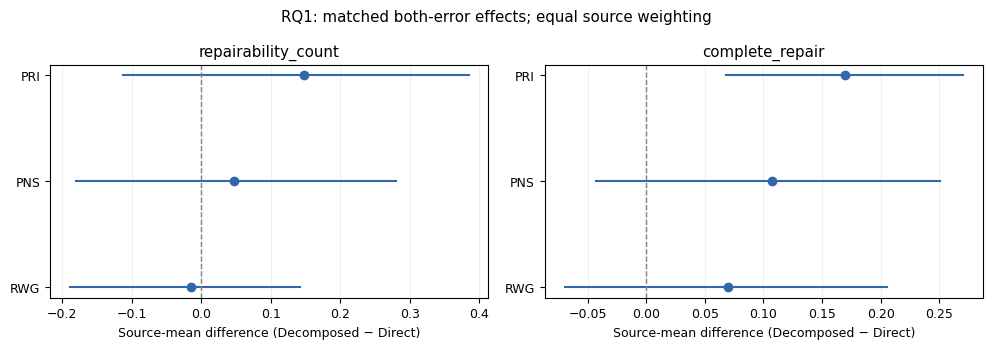

In [8]:
RECOVERY_METRICS=["repairability_count","complete_repair","wrong_before","wrong_after","wrong_claim_reduction","hall_rate_reduction_abs","hall_rate_reduction_rel","claims_before","claims_after","claim_count_change","TQS","CQS","total_runtime_sec"]
paired=match_frames(eligible[eligible.config.eq("Direct+HDM")],eligible[eligible.config.eq("Decomposed+HDM")],RECOVERY_METRICS)
attrition=[]
for task in TASK_ORDER:
    a=initial[(initial.task.eq(task))&initial.config.eq("Direct+HDM")]
    b=initial[(initial.task.eq(task))&initial.config.eq("Decomposed+HDM")]
    joined=pre_pairs[pre_pairs.task.eq(task)]
    both=joined.initial_error_direct.eq(1)&joined.initial_error_decomp.eq(1)
    g=paired[paired.task.eq(task)]
    attrition.append({"task":task,"Direct_valid_pre":len(a),"Decomposed_valid_pre":len(b),"valid_pre_matched":len(joined),"both_error_pre_pairs":int(both.sum()),"valid_pre_post_both_error_pairs":len(g),"recovery_sources":g.instance_id.nunique(),"Direct_only_valid_pre":len(a)-len(joined),"Decomposed_only_valid_pre":len(b)-len(joined)})
show_table("rq1_matching_attrition",pd.DataFrame(attrition))
rq1_primary=comparisons(paired,["repairability_count","complete_repair"],family="RQ1_primary_effectiveness")
rq1_secondary=comparisons(paired,["wrong_claim_reduction","hall_rate_reduction_abs","hall_rate_reduction_rel"],family="RQ1_secondary_recovery")
show_table("rq1_primary_matched",rq1_primary); show_table("rq1_secondary_matched",rq1_secondary)
show_table("rq1_matched_burden_descriptive",comparisons(paired,["wrong_before","wrong_after","claims_before","claims_after"],family="RQ1_burden_context").drop(columns=["p_mean","p_holm","reject_holm","p_signed_rank_sensitivity","rank_biserial_sensitivity"]))
complete_discordance=[]
for task,g in paired.groupby("task"):
    a,b=g.complete_repair_direct.eq(1),g.complete_repair_decomp.eq(1)
    complete_discordance.append({"task":task,"Direct_only_complete":int((a&~b).sum()),"Decomposed_only_complete":int((~a&b).sum()),"both_complete":int((a&b).sum()),"neither_complete":int((~a&~b).sum())})
show_table("rq1_complete_discordance_descriptive",pd.DataFrame(complete_discordance))
delta_plot(rq1_primary,["repairability_count","complete_repair"],"rq1_matched_summary","RQ1: matched both-error effects; equal source weighting")

### 4.4 Robustness: model, temperature, severity, and averaging choice

In [9]:
rq1_model=comparisons(paired,["repairability_count","complete_repair"],groups=("task","model_label"),family="RQ1_model_robustness")
rq1_temperature=comparisons(paired,["repairability_count","complete_repair"],groups=("task","generation_temperature_unified"),family="RQ1_temperature_robustness")
show_table("rq1_matched_by_model",rq1_model);show_table("rq1_matched_by_temperature",rq1_temperature)
sensitivity=[]
for task,g in paired.groupby("task"):
    for metric in ["repairability_count","complete_repair"]:
        v=g[MATCH_KEYS+[f"{metric}_direct",f"{metric}_decomp"]].dropna().copy()
        v["d"]=v[f"{metric}_decomp"]-v[f"{metric}_direct"]
        bymodel=v.groupby(["instance_id","model_label"]).d.mean()
        source=bymodel.groupby("instance_id").mean()
        sensitivity.append({"task":task,"metric":metric,"sources":len(source),"equal_available_model_delta":source.mean(),"primary_source_delta":rq1_primary.loc[rq1_primary.task.eq(task)&rq1_primary.metric.eq(metric),"delta"].iloc[0]})
show_table("rq1_weighting_sensitivity",pd.DataFrame(sensitivity))
pooled=[]
for metric in ["repairability_count","complete_repair"]:
    source_groups=[]
    for task,g in paired.groupby("task"):
        a,b=f"{metric}_direct",f"{metric}_decomp"
        v=g.dropna(subset=[a,b]).copy();v["d"]=v[b]-v[a]
        vals=v.groupby("instance_id").d.mean().to_numpy()
        if len(vals):source_groups.append(vals)
    rng=rng_for(("equal_task",metric));boot=[]
    if len(source_groups)==len(TASK_ORDER) and all(len(x)>=2 for x in source_groups):
        for _ in range(N_BOOT):boot.append(np.mean([rng.choice(x,len(x),replace=True).mean() for x in source_groups]))
        lo,hi=np.quantile(boot,[.025,.975]);mean=np.mean([x.mean() for x in source_groups])
    else: mean=lo=hi=np.nan
    pooled.append({"metric":metric,"equal_task_delta":mean,"ci95_low":lo,"ci95_high":hi,"interpretation":"supplementary; no pooled significance claim"})
show_table("rq1_equal_task_pooled_supplement",pd.DataFrame(pooled))
eligible["severity_bin"]=pd.cut(eligible.wrong_before,[0,1,2,3,5,np.inf],labels=["1","2","3","4–5","6+"],include_lowest=False)
eligible["density_bin"]=pd.cut(eligible.hall_rate_before,[0,.1,.2,.4,.6,1],labels=["(0,.1]","(.1,.2]","(.2,.4]","(.4,.6]","(.6,1]"],include_lowest=False)
show_table("rq1_severity_descriptive",descriptive_summary(eligible,["task","config","severity_bin"],["repairability_count","complete_repair"]))
show_table("rq1_density_descriptive",descriptive_summary(eligible,["task","config","density_bin"],["repairability_count","complete_repair"]))
# Claim extraction drift is a necessary context for net error reduction.
show_table("rq1_claim_extraction_change",descriptive_summary(eligible,["task","config"],["claim_count_change","claims_before","claims_after"]))

,task,model_label,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,DeepSeek-R1,repairability_count,258,89,0.292687,0.477629,0.184942,-0.129501,0.497787,0.262150,0.038939,0.267405,0.218725,RQ1_model_robustness,1.00000,False
1,Project Ideation,DeepSeek-R1,complete_repair,258,89,0.454133,0.632772,0.178638,0.063289,0.297205,0.004850,0.004977,0.419638,0.158915,RQ1_model_robustness,0.08245,False
2,Project Ideation,Gemma3,repairability_count,20,16,0.645833,0.640625,-0.005208,-0.494792,0.468750,1.000000,0.952303,0.022222,0.112500,RQ1_model_robustness,1.00000,False
3,Project Ideation,Gemma3,complete_repair,20,16,0.666667,0.750000,0.083333,-0.250000,0.416667,0.726562,0.651077,0.166667,0.200000,RQ1_model_robustness,1.00000,False
4,Project Ideation,Qwen3,repairability_count,76,42,0.519700,0.695323,0.175624,-0.177729,0.528870,0.343000,0.108334,0.409524,0.106798,RQ1_model_robustness,1.00000,False
5,Project Ideation,Qwen3,complete_repair,76,42,0.667857,0.784524,0.116667,-0.035714,0.271429,0.184300,0.173409,0.375000,0.118421,RQ1_model_robustness,1.00000,False
6,Public Narrative Synthesis,DeepSeek-R1,repairability_count,75,26,0.658579,0.647791,-0.010788,-0.284626,0.251473,0.942150,0.826873,0.058480,-0.058370,RQ1_model_robustness,1.00000,False
7,Public Narrative Synthesis,DeepSeek-R1,complete_repair,75,26,0.637592,0.657647,0.020055,-0.228858,0.268773,0.882650,0.907977,0.033333,0.040000,RQ1_model_robustness,1.00000,False
8,Public Narrative Synthesis,Gemma3,repairability_count,79,31,0.145059,0.369560,0.224501,-0.116290,0.574549,0.219200,0.182777,0.304615,0.133605,RQ1_model_robustness,1.00000,False
9,Public Narrative Synthesis,Gemma3,complete_repair,79,31,0.210753,0.502458,0.291705,0.133022,0.445015,0.001500,0.002827,0.816993,0.316456,RQ1_model_robustness,0.02700,True


,task,generation_temperature_unified,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,0.0,repairability_count,115,36,0.607190,0.477469,-0.129721,-0.774475,0.295721,0.81045,0.098588,0.411255,-0.260190,RQ1_temperature_robustness,1.00000,False
1,Project Ideation,0.0,complete_repair,115,36,0.458333,0.772222,0.313889,0.113889,0.500000,0.00480,0.003451,0.719298,0.234783,RQ1_temperature_robustness,0.08160,False
2,Project Ideation,0.5,repairability_count,118,74,0.082653,0.545135,0.462482,0.040442,0.987981,0.05825,0.266384,0.173737,0.354395,RQ1_temperature_robustness,0.87375,False
3,Project Ideation,0.5,complete_repair,118,74,0.546171,0.594595,0.048423,-0.083333,0.179054,0.48155,0.386320,0.157895,0.025424,RQ1_temperature_robustness,1.00000,False
4,Project Ideation,1.0,repairability_count,121,70,0.328502,0.670391,0.341889,0.046182,0.662862,0.02965,0.019767,0.351841,0.453727,RQ1_temperature_robustness,0.47440,False
5,Project Ideation,1.0,complete_repair,121,70,0.458333,0.685714,0.227381,0.085714,0.371429,0.00315,0.002555,0.505314,0.198347,RQ1_temperature_robustness,0.05670,False
6,Public Narrative Synthesis,0.0,repairability_count,72,18,0.599140,0.268519,-0.330622,-0.838891,0.153110,0.23580,0.292733,-0.329670,-0.237946,RQ1_temperature_robustness,1.00000,False
7,Public Narrative Synthesis,0.0,complete_repair,72,18,0.453704,0.527778,0.074074,-0.222222,0.352315,0.72110,0.651077,0.166667,0.125000,RQ1_temperature_robustness,1.00000,False
8,Public Narrative Synthesis,0.5,repairability_count,63,33,0.372593,0.526599,0.154006,-0.229521,0.595818,0.54375,0.501664,0.156667,0.029693,RQ1_temperature_robustness,1.00000,False
9,Public Narrative Synthesis,0.5,complete_repair,63,33,0.461616,0.613131,0.151515,-0.015152,0.318182,0.10940,0.103988,0.485714,0.158730,RQ1_temperature_robustness,1.00000,False


,task,metric,sources,equal_available_model_delta,primary_source_delta
0,Project Ideation,repairability_count,94,0.066737,0.147359
1,Project Ideation,complete_repair,94,0.150954,0.169360
2,Public Narrative Synthesis,repairability_count,42,0.068287,0.047683
3,Public Narrative Synthesis,complete_repair,42,0.122402,0.107012
4,Related Work,repairability_count,58,-0.018103,-0.014936
5,Related Work,complete_repair,58,0.071695,0.069663


,metric,equal_task_delta,ci95_low,ci95_high,interpretation
0,repairability_count,0.060035,-0.070562,0.180048,supplementary; no pooled significance claim
1,complete_repair,0.115345,0.038174,0.190664,supplementary; no pooled significance claim


,task,config,severity_bin,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,1,repairability_count,264,88,0.492505,0.518939,1.000000,0.282087,0.675862
1,Project Ideation,Decomposed+HDM,1,complete_repair,264,88,0.728869,0.746212,1.000000,0.653596,0.801520
2,Project Ideation,Decomposed+HDM,2,repairability_count,118,60,0.612731,0.546610,1.000000,0.406481,0.783333
3,Project Ideation,Decomposed+HDM,2,complete_repair,118,60,0.715741,0.677966,1.000000,0.612477,0.810208
4,Project Ideation,Decomposed+HDM,3,repairability_count,56,35,0.885714,0.886905,1.000000,0.800000,0.957143
5,Project Ideation,Decomposed+HDM,3,complete_repair,56,35,0.800000,0.803571,1.000000,0.671429,0.914286
6,Project Ideation,Decomposed+HDM,4–5,repairability_count,66,43,0.766473,0.763636,1.000000,0.656560,0.866284
7,Project Ideation,Decomposed+HDM,4–5,complete_repair,66,43,0.637597,0.636364,1.000000,0.501890,0.767490
8,Project Ideation,Decomposed+HDM,6+,repairability_count,83,49,0.805813,0.813104,1.000000,0.707443,0.891935
9,Project Ideation,Decomposed+HDM,6+,complete_repair,83,49,0.608844,0.590361,1.000000,0.482951,0.732993


,task,config,density_bin,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,"(0,.1]",repairability_count,252,89,0.519663,0.501984,1.000000,0.340801,0.674615
1,Project Ideation,Decomposed+HDM,"(0,.1]",complete_repair,252,89,0.730471,0.734127,1.000000,0.656554,0.800831
2,Project Ideation,Decomposed+HDM,"(.1,.2]",repairability_count,172,78,0.680146,0.632849,1.000000,0.535468,0.809392
3,Project Ideation,Decomposed+HDM,"(.1,.2]",complete_repair,172,78,0.728348,0.691860,1.000000,0.642156,0.809699
4,Project Ideation,Decomposed+HDM,"(.2,.4]",repairability_count,79,49,0.807418,0.804732,1.000000,0.708914,0.891093
5,Project Ideation,Decomposed+HDM,"(.2,.4]",complete_repair,79,49,0.676190,0.708861,1.000000,0.557143,0.792517
6,Project Ideation,Decomposed+HDM,"(.4,.6]",repairability_count,49,35,0.828422,0.861829,1.000000,0.718039,0.914594
7,Project Ideation,Decomposed+HDM,"(.4,.6]",complete_repair,49,35,0.614286,0.693878,1.000000,0.457143,0.757143
8,Project Ideation,Decomposed+HDM,"(.6,1]",repairability_count,35,23,0.832103,0.797167,1.000000,0.696278,0.937742
9,Project Ideation,Decomposed+HDM,"(.6,1]",complete_repair,35,23,0.591304,0.542857,1.000000,0.413043,0.769565


,task,config,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,claim_count_change,587,100,-0.712913,-0.827939,-0.666667,-1.134219,-0.304907
1,Project Ideation,Decomposed+HDM,claims_before,587,100,14.999679,15.175468,14.857143,14.590433,15.386659
2,Project Ideation,Decomposed+HDM,claims_after,587,100,14.286766,14.347530,14.333333,13.877273,14.704708
3,Project Ideation,Direct+HDM,claim_count_change,1485,100,-0.887923,-0.863973,-0.854167,-1.071809,-0.703718
4,Project Ideation,Direct+HDM,claims_before,1485,100,14.040451,14.023569,13.843750,13.767557,14.320193
5,Project Ideation,Direct+HDM,claims_after,1485,100,13.152528,13.159596,13.047619,12.890349,13.427955
6,Public Narrative Synthesis,Decomposed+HDM,claim_count_change,335,51,0.314680,0.537313,0.125000,-0.244341,0.940086
7,Public Narrative Synthesis,Decomposed+HDM,claims_before,335,51,12.857392,12.274627,12.800000,11.799883,13.912209
8,Public Narrative Synthesis,Decomposed+HDM,claims_after,335,51,13.172072,12.811940,12.400000,11.991075,14.406962
9,Public Narrative Synthesis,Direct+HDM,claim_count_change,588,55,-0.559378,-0.445578,-0.500000,-1.185511,0.113799


## 5. RQ2 - error and execution-trace characteristics
### 5.1 Initial wrong-claim composition and attributed origin

Decomposed eligible outputs: 1305 initial erroneous claims: 2839


,task,config,claim_type,size,percentage_of_detected_errors
0,Project Ideation,Decomposed+HDM,broader_impact,75,4.368084
1,Project Ideation,Decomposed+HDM,dataset_or_resource,8,0.465929
2,Project Ideation,Decomposed+HDM,evaluation_plan,37,2.154921
3,Project Ideation,Decomposed+HDM,expected_contribution,75,4.368084
4,Project Ideation,Decomposed+HDM,future_objective,450,26.208503
...,...,...,...,...,...
56,Related Work,Direct+HDM,method,263,22.497861
57,Related Work,Direct+HDM,number,6,0.513259
58,Related Work,Direct+HDM,other,94,8.041061
59,Related Work,Direct+HDM,result,133,11.377246


,task,accountable_stage,size,percent
0,Project Ideation,executor,1159,67.501456
1,Project Ideation,synthesizer,558,32.498544
2,Public Narrative Synthesis,executor,264,47.058824
3,Public Narrative Synthesis,synthesizer,291,51.871658
4,Public Narrative Synthesis,unknown,6,1.069519
5,Related Work,executor,72,12.834225
6,Related Work,synthesizer,489,87.165775


,task,claim_type,accountable_stage,size,percent_within_type
0,Project Ideation,broader_impact,executor,28,37.333333
1,Project Ideation,broader_impact,synthesizer,47,62.666667
2,Project Ideation,dataset_or_resource,executor,2,25.000000
3,Project Ideation,dataset_or_resource,synthesizer,6,75.000000
4,Project Ideation,evaluation_plan,executor,27,72.972973
5,Project Ideation,evaluation_plan,synthesizer,10,27.027027
6,Project Ideation,expected_contribution,executor,39,52.000000
7,Project Ideation,expected_contribution,synthesizer,36,48.000000
8,Project Ideation,future_objective,executor,353,78.444444
9,Project Ideation,future_objective,synthesizer,97,21.555556


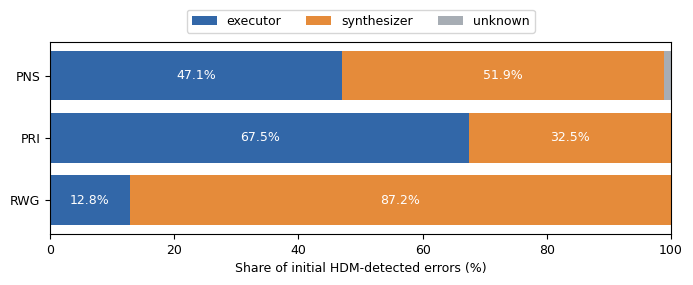

In [10]:
claim_rows=[]
for _,row in eligible.iterrows():
    h=audit_hdm(row.hdm_before_json)["hdm"]
    cmap={str(c["claim_id"]).strip():c for c in h["extracted_claims"]}
    for c in h["claim_verifications"]:
        label=str(c["label"]).strip().lower()
        if label=="supported":continue
        extracted=cmap[str(c["claim_id"]).strip()]
        stage=str(c.get("accountable_stage","unknown")).strip().lower()
        if stage not in ("executor","synthesizer","unknown"):stage="unknown"
        claim_rows.append({**{k:row[k] for k in MATCH_KEYS},"record_id":row.record_id,"config":row.config,"claim_id":str(c["claim_id"]).strip(),
                           "claim_type":str(extracted.get("claim_type","unknown")).strip() or "unknown","verification_label":label,
                           "accountable_stage":stage,"agent_contribution":str(c.get("agent_contribution","unknown")),
                           "provenance_confidence":finite_number(c.get("provenance_confidence")) if 0<=finite_number(c.get("provenance_confidence"))<=1 else np.nan,
                           "assignment_status":str(c.get("provenance_pair_status","not_recorded")),
                           "excluded_from_retrigger":strict_bool(c.get("excluded_from_retrigger",False))})
claims=pd.DataFrame(claim_rows,columns=MATCH_KEYS+["record_id","config","claim_id","claim_type","verification_label","accountable_stage","agent_contribution","provenance_confidence","assignment_status","excluded_from_retrigger"])
claims_rq2=claims[claims.config.eq("Decomposed+HDM")].copy()
print("Decomposed eligible outputs:",int(eligible.config.eq("Decomposed+HDM").sum()),"initial erroneous claims:",len(claims_rq2))
type_composition=claims.groupby(["task","config","claim_type"],as_index=False).size()
type_composition["percentage_of_detected_errors"]=100*type_composition["size"]/type_composition.groupby(["task","config"])["size"].transform("sum")
show_table("rq2_error_type_composition_both_workflows",type_composition)
origin=claims_rq2.groupby(["task","accountable_stage"],as_index=False).size()
origin["percent"]=100*origin["size"]/origin.groupby("task")["size"].transform("sum")
show_table("rq2_attributed_origin",origin)
origin_type=claims_rq2.groupby(["task","claim_type","accountable_stage"],as_index=False).size()
origin_type["percent_within_type"]=100*origin_type["size"]/origin_type.groupby(["task","claim_type"])["size"].transform("sum")
show_table("rq2_type_attributed_origin",origin_type)
fig,ax=plt.subplots(figsize=(7,3))
pivot=origin.pivot(index="task",columns="accountable_stage",values="percent").reindex(TASK_ORDER).fillna(0)
left=np.zeros(len(pivot))
for stage,color in [("executor","#3267A8"),("synthesizer","#E58B3A"),("unknown","#A7ADB4")]:
    values=pivot.get(stage,pd.Series(0,index=pivot.index)).to_numpy()
    ax.barh(np.arange(len(pivot)),values,left=left,label=stage,color=color)
    for i,v in enumerate(values):
        if v>=7:ax.text(left[i]+v/2,i,f"{v:.1f}%",ha="center",va="center",color="white")
    left+=values
ax.set_yticks(np.arange(len(pivot)),[TASK_SHORT[x] for x in pivot.index]);ax.invert_yaxis();ax.set_xlim(0,100)
ax.set_xlabel("Share of initial HDM-detected errors (%)");ax.legend(ncol=3,loc="upper center",bbox_to_anchor=(.5,1.2))
fig.tight_layout();save_figure(fig,"rq2_error_origin")

### 5.2 Actual intervention, route, and assignment checks

In [11]:
def list_from_row_or_report(row,column,report,key):
    value=row.get(column)
    if not is_missing(value):return parse_json(value,list)
    val=report.get(key)
    return val if isinstance(val,list) else None

def trace_features(row):
    report=parse_json(row.get("repair_report_json"),dict) or {}
    performed=strict_bool(row.get("repair_performed"))
    if performed is None:performed=strict_bool(report.get("repair_performed"))
    replay=list_from_row_or_report(row,"retriggered_subtasks_json",report,"retriggered_subtasks")
    downstream=list_from_row_or_report(row,"downstream_retriggered_subtasks_json",report,"downstream_retriggered_subtasks")
    targets=list_from_row_or_report(row,"accountable_feedback_targets_json",report,"accountable_feedback_targets")
    planner=parse_json(row.get("planner_output_json"),dict)
    subs=planner.get("Subtasks",planner.get("subtasks")) if planner else None
    ids=[str(x["subtask_id"]) for x in subs] if isinstance(subs,list) and all(isinstance(x,dict) and x.get("subtask_id") is not None for x in subs) else []
    plan_valid=bool(ids) and len(set(ids))==len(ids)
    replay_ids=[str(x) for x in replay] if replay is not None else None
    replay_valid=replay_ids is not None and len(set(replay_ids))==len(replay_ids) and (not replay_ids or (plan_valid and set(replay_ids).issubset(ids)))
    if performed is False: route="No intervention"
    elif performed is True and replay_valid:route="Executor replay + synthesis" if replay_ids else "Synthesizer only"
    else:route="Indeterminate report"
    if performed is False and replay_ids:route="Indeterminate report"
    count=len(replay_ids) if replay_valid else np.nan
    position=np.nan
    if plan_valid and route=="Synthesizer only":position=1.
    elif plan_valid and route=="Executor replay + synthesis":position=(min(ids.index(x) for x in replay_ids)+1)/(len(ids)+1)
    stored_earliest=first_nonempty(row,["earliest_retriggered_subtask"]) or str(report.get("earliest_retriggered_subtask", ""))
    expected_earliest=min(replay_ids,key=ids.index) if plan_valid and replay_valid and replay_ids else ""
    h=audit_hdm(row.hdm_before_json)["hdm"]
    invalid=h.get("invalid_provenance_claims")
    invalid_count=len(invalid) if isinstance(invalid,list) else finite_number(row.get("invalid_provenance_claim_count"))
    return {"record_id":row.record_id,"repair_route":route,"repair_attempted":float(performed) if performed is not None else np.nan,
            "retriggered_subtask_count":count,"downstream_retrigger_count":len(downstream) if downstream is not None else np.nan,
            "accountable_target_count":len(targets) if targets is not None else np.nan,"plan_subtasks":len(ids) if plan_valid else np.nan,
            "replay_fraction":count/len(ids) if plan_valid and np.isfinite(count) else np.nan,"intervention_position":position,
            "earliest_report_disagrees":bool(expected_earliest and stored_earliest not in (expected_earliest,"","None","nan")),
            "invalid_assignment_count":invalid_count,"invalid_assignment_fraction":invalid_count/row.wrong_before if np.isfinite(invalid_count) else np.nan}

rq2=eligible[eligible.config.eq("Decomposed+HDM")].copy()
trace=pd.DataFrame([trace_features(row) for _,row in rq2.iterrows()],columns=["record_id","repair_route","repair_attempted","retriggered_subtask_count","downstream_retrigger_count","accountable_target_count","plan_subtasks","replay_fraction","intervention_position","earliest_report_disagrees","invalid_assignment_count","invalid_assignment_fraction"])
rq2=rq2.merge(trace,on="record_id",validate="one_to_one")
run_confidence=claims_rq2.groupby("record_id").provenance_confidence.mean()
rq2["mean_model_reported_provenance_confidence"]=rq2.record_id.map(run_confidence)
stage_profile=claims_rq2.groupby("record_id").accountable_stage.agg(lambda x: "Mixed executor/synthesis" if {"executor","synthesizer"}.issubset(set(x)) else "Contains executor" if "executor" in set(x) else "Synthesizer only" if set(x)=={"synthesizer"} else "Contains unknown")
rq2["attributed_stage_profile"]=rq2.record_id.map(stage_profile)
show_table("rq2_stage_profile_outcomes_descriptive",descriptive_summary(rq2,["task","attributed_stage_profile"],["wrong_before","repairability_count","complete_repair"]))
show_table("rq2_model_reported_confidence_descriptive",descriptive_summary(rq2,["task"],["mean_model_reported_provenance_confidence"]))
show_table("rq2_trace_audit",rq2[MATCH_KEYS+["record_id"]+[x for x in trace if x!="record_id"]])
route_counts=rq2.groupby(["task","repair_route"],as_index=False).size()
route_counts["run_percent"]=100*route_counts["size"]/route_counts.groupby("task")["size"].transform("sum")
show_table("rq2_actual_route_counts",route_counts)
show_table("rq2_route_outcomes_descriptive",descriptive_summary(rq2,["task","repair_route"],["wrong_before","wrong_after","repairability_count","complete_repair"]))
show_table("rq2_route_model_severity_context",descriptive_summary(rq2,["task","model_label","repair_route"],["wrong_before","repairability_count","complete_repair"]))
show_table("rq2_trace_summary",descriptive_summary(rq2,["task"],["repair_attempted","replay_fraction","intervention_position","invalid_assignment_fraction"]))

,task,attributed_stage_profile,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Contains executor,wrong_before,304,96,3.246677,3.269737,2.600000,2.787621,3.749991
1,Project Ideation,Contains executor,repairability_count,304,96,0.604510,0.576596,0.866071,0.453833,0.730059
2,Project Ideation,Contains executor,complete_repair,304,96,0.662897,0.664474,0.666667,0.590002,0.729169
3,Project Ideation,Mixed executor/synthesis,wrong_before,50,28,5.855357,5.840000,5.350000,4.576652,7.337545
4,Project Ideation,Mixed executor/synthesis,repairability_count,50,28,0.757968,0.776571,1.000000,0.497773,0.932652
5,Project Ideation,Mixed executor/synthesis,complete_repair,50,28,0.696429,0.680000,1.000000,0.535714,0.839286
6,Project Ideation,Synthesizer only,wrong_before,233,85,2.006433,1.849785,1.500000,1.698017,2.369378
7,Project Ideation,Synthesizer only,repairability_count,233,85,0.656201,0.664981,1.000000,0.480539,0.801687
8,Project Ideation,Synthesizer only,complete_repair,233,85,0.766303,0.759657,1.000000,0.693957,0.835757
9,Public Narrative Synthesis,Contains executor,wrong_before,135,46,1.560870,1.711111,1.225000,1.361594,1.782246


,task,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,mean_model_reported_provenance_confidence,587,100,0.854345,0.842834,0.862000,0.840987,0.867011
1,Public Narrative Synthesis,mean_model_reported_provenance_confidence,335,51,0.771703,0.777900,0.783333,0.737521,0.800213
2,Related Work,mean_model_reported_provenance_confidence,383,92,0.722168,0.715697,0.736667,0.698335,0.745664


,task,model_label,instance_id,generation_temperature_unified,run_id,record_id,repair_route,repair_attempted,retriggered_subtask_count,downstream_retrigger_count,accountable_target_count,plan_subtasks,replay_fraction,intervention_position,earliest_report_disagrees,invalid_assignment_count,invalid_assignment_fraction
0,Public Narrative Synthesis,Gemma3,1,0.0,1,4296,Synthesizer only,1.0,0.0,0.0,0.0,6,0.00,1.000000,False,0,0.0
1,Public Narrative Synthesis,Gemma3,11,0.0,1,4306,Synthesizer only,1.0,0.0,0.0,0.0,7,0.00,1.000000,False,0,0.0
2,Public Narrative Synthesis,Gemma3,14,0.0,1,4309,Executor replay + synthesis,1.0,5.0,4.0,1.0,5,1.00,0.166667,False,0,0.0
3,Public Narrative Synthesis,Gemma3,18,0.0,1,4312,Executor replay + synthesis,1.0,6.0,5.0,1.0,6,1.00,0.142857,False,0,0.0
4,Public Narrative Synthesis,Gemma3,26,0.0,1,4319,Executor replay + synthesis,1.0,5.0,4.0,1.0,5,1.00,0.166667,False,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Project Ideation,DeepSeek-R1,2534875,1.0,3,26956,Executor replay + synthesis,1.0,3.0,2.0,1.0,4,0.75,0.400000,False,0,0.0
1301,Project Ideation,DeepSeek-R1,2603392,1.0,3,26957,Executor replay + synthesis,1.0,4.0,1.0,3.0,5,0.80,0.333333,False,0,0.0
1302,Project Ideation,DeepSeek-R1,2525849,1.0,3,26958,Synthesizer only,1.0,0.0,0.0,0.0,5,0.00,1.000000,False,0,0.0
1303,Project Ideation,DeepSeek-R1,2545538,1.0,3,26959,Executor replay + synthesis,1.0,3.0,0.0,3.0,4,0.75,0.400000,False,0,0.0


,task,repair_route,size,run_percent
0,Project Ideation,Executor replay + synthesis,350,59.625213
1,Project Ideation,No intervention,3,0.511073
2,Project Ideation,Synthesizer only,234,39.863714
3,Public Narrative Synthesis,Executor replay + synthesis,151,45.074627
4,Public Narrative Synthesis,No intervention,4,1.194030
5,Public Narrative Synthesis,Synthesizer only,180,53.731343
6,Related Work,Executor replay + synthesis,43,11.227154
7,Related Work,Synthesizer only,340,88.772846


,task,repair_route,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Executor replay + synthesis,wrong_before,350,97,3.459716,3.660000,3.000000,2.995321,3.959291
1,Project Ideation,Executor replay + synthesis,wrong_after,350,97,0.822423,0.917143,0.500000,0.601593,1.072988
2,Project Ideation,Executor replay + synthesis,repairability_count,350,97,0.627799,0.608897,0.870370,0.472021,0.748983
3,Project Ideation,Executor replay + synthesis,complete_repair,350,97,0.689805,0.671429,0.714286,0.624225,0.750347
4,Project Ideation,No intervention,wrong_before,3,3,1.000000,1.000000,1.000000,1.000000,1.000000
5,Project Ideation,No intervention,wrong_after,3,3,1.000000,1.000000,1.000000,1.000000,1.000000
6,Project Ideation,No intervention,repairability_count,3,3,0.000000,0.000000,0.000000,0.000000,0.000000
7,Project Ideation,No intervention,complete_repair,3,3,0.000000,0.000000,0.000000,0.000000,0.000000
8,Project Ideation,Synthesizer only,wrong_before,234,86,2.006358,1.850427,1.583333,1.708154,2.383169
9,Project Ideation,Synthesizer only,wrong_after,234,86,0.560271,0.538462,0.000000,0.308044,0.900615


,task,model_label,repair_route,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,DeepSeek-R1,Executor replay + synthesis,wrong_before,292,93,3.766487,3.869863,3.000000,3.218598,4.341770
1,Project Ideation,DeepSeek-R1,Executor replay + synthesis,repairability_count,292,93,0.588668,0.560607,0.833333,0.397260,0.732947
2,Project Ideation,DeepSeek-R1,Executor replay + synthesis,complete_repair,292,93,0.669534,0.643836,0.750000,0.598741,0.736922
3,Project Ideation,DeepSeek-R1,Synthesizer only,wrong_before,74,50,2.182333,2.013514,1.000000,1.572333,2.891700
4,Project Ideation,DeepSeek-R1,Synthesizer only,repairability_count,74,50,0.482333,0.542793,1.000000,0.206317,0.721333
...,...,...,...,...,...,...,...,...,...,...,...
61,Related Work,Qwen3,Executor replay + synthesis,repairability_count,8,6,-0.166667,-0.125000,0.000000,-1.333333,0.666667
62,Related Work,Qwen3,Executor replay + synthesis,complete_repair,8,6,0.333333,0.250000,0.000000,0.000000,0.666667
63,Related Work,Qwen3,Synthesizer only,wrong_before,145,66,1.271465,1.386207,1.000000,1.163630,1.405562
64,Related Work,Qwen3,Synthesizer only,repairability_count,145,66,0.767340,0.717241,1.000000,0.673064,0.856319


,task,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,repair_attempted,587,100,0.993571,0.994889,1.000000,0.985000,1.000000
1,Project Ideation,replay_fraction,584,100,0.454956,0.452960,0.464286,0.414369,0.495919
2,Project Ideation,intervention_position,584,100,0.620428,0.620991,0.610867,0.588465,0.654806
3,Project Ideation,invalid_assignment_fraction,587,100,0.007447,0.006672,0.000000,0.001019,0.016154
4,Public Narrative Synthesis,repair_attempted,335,51,0.966667,0.988060,1.000000,0.931373,0.996078
5,Public Narrative Synthesis,replay_fraction,335,51,0.383300,0.378767,0.386667,0.309476,0.458780
6,Public Narrative Synthesis,intervention_position,331,51,0.675254,0.682922,0.670476,0.610219,0.740536
7,Public Narrative Synthesis,invalid_assignment_fraction,335,51,0.035294,0.013433,0.000000,0.005882,0.070588
8,Related Work,repair_attempted,383,92,1.000000,1.000000,1.000000,1.000000,1.000000
9,Related Work,replay_fraction,383,92,0.057929,0.067040,0.000000,0.035168,0.082907


### 5.3 Associations with repair outcomes

In [12]:
profiles=claims.groupby("record_id").verification_label.agg(lambda x:"Contains contradiction" if "contradicted" in set(x) else "Unsupported only")
eligible["verification_profile"]=eligible.record_id.map(profiles)
rq2["verification_profile"]=rq2.record_id.map(profiles)
show_table("rq2_verification_profiles_both_workflows",descriptive_summary(eligible,["task","config","verification_profile"],["wrong_before","repairability_count","complete_repair"]))
run_types=claims[["record_id","claim_type"]].drop_duplicates().merge(eligible[["record_id"]+MATCH_KEYS+["config","wrong_before","repairability_count","complete_repair"]],on="record_id",validate="many_to_one")
show_table("rq2_whole_run_outcomes_containing_type",descriptive_summary(run_types,["task","config","claim_type"],["wrong_before","repairability_count","complete_repair"]))
executor_repairs=rq2[rq2.repair_route.eq("Executor replay + synthesis")].copy()
executor_repairs["breadth_bin"]=pd.cut(executor_repairs.retriggered_subtask_count,[0,2,4,np.inf],labels=["1–2","3–4","5+"],include_lowest=False)
show_table("rq2_replay_breadth_descriptive",descriptive_summary(executor_repairs,["task","breadth_bin"],["wrong_before","repairability_count","complete_repair"]))
executor_repairs["position_bin"]=pd.cut(executor_repairs.intervention_position,[0,1/3,2/3,1],labels=["early","middle","late"],include_lowest=True)
show_table("rq2_executor_position_descriptive",descriptive_summary(executor_repairs,["task","position_bin"],["wrong_before","repairability_count","complete_repair"]))
correlations=[]
for task,g in executor_repairs.groupby("task"):
    for feature in ["retriggered_subtask_count","replay_fraction","intervention_position","wrong_before","hall_rate_before"]:
        for outcome in ["repairability_count","complete_repair"]:
            # Same complete observations are used for both source means.
            x=g[SOURCE_KEYS+[feature,outcome]].replace([np.inf,-np.inf],np.nan).dropna()
            source=x.groupby(SOURCE_KEYS)[[feature,outcome]].mean()
            rho=float(spearmanr(source[feature],source[outcome]).statistic) if len(source)>=3 and source[feature].nunique()>1 and source[outcome].nunique()>1 else np.nan
            correlations.append({"task":task,"feature":feature,"outcome":outcome,"executor_rows":len(x),"sources":len(source),"source_spearman_rho_descriptive":rho})
show_table("rq2_executor_correlations_descriptive",pd.DataFrame(correlations))
# Assignment-invalid errors are counted separately, never relabeled as validated origins.
show_table("rq2_assignment_status_claim_counts",claims_rq2.groupby(["task","accountable_stage","assignment_status","excluded_from_retrigger"],dropna=False,as_index=False).size())

,task,config,verification_profile,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,Contains contradiction,wrong_before,49,36,1.555556,1.428571,1.000000,1.208333,2.027778
1,Project Ideation,Decomposed+HDM,Contains contradiction,repairability_count,49,36,0.780093,0.814626,1.000000,0.650463,0.898148
2,Project Ideation,Decomposed+HDM,Contains contradiction,complete_repair,49,36,0.754630,0.795918,1.000000,0.611111,0.879630
3,Project Ideation,Decomposed+HDM,Unsupported only,wrong_before,538,100,3.050065,3.061338,2.708333,2.720590,3.406088
4,Project Ideation,Decomposed+HDM,Unsupported only,repairability_count,538,100,0.616178,0.611780,0.797619,0.498456,0.720407
5,Project Ideation,Decomposed+HDM,Unsupported only,complete_repair,538,100,0.705090,0.695167,0.738636,0.654469,0.755031
6,Project Ideation,Direct+HDM,Contains contradiction,wrong_before,69,42,4.559524,4.884058,3.250000,3.434375,5.910714
7,Project Ideation,Direct+HDM,Contains contradiction,repairability_count,69,42,0.412338,0.499177,1.000000,-0.024538,0.778418
8,Project Ideation,Direct+HDM,Contains contradiction,complete_repair,69,42,0.690476,0.681159,1.000000,0.547619,0.821429
9,Project Ideation,Direct+HDM,Unsupported only,wrong_before,1416,100,4.088376,4.110876,3.834821,3.838840,4.339685


,task,config,claim_type,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,Decomposed+HDM,broader_impact,wrong_before,64,35,4.270000,4.281250,3.0,3.092821,5.628714
1,Project Ideation,Decomposed+HDM,broader_impact,repairability_count,64,35,0.817860,0.726119,1.0,0.583098,0.967358
2,Project Ideation,Decomposed+HDM,broader_impact,complete_repair,64,35,0.824286,0.812500,1.0,0.700000,0.932964
3,Project Ideation,Decomposed+HDM,dataset_or_resource,wrong_before,8,8,4.500000,4.500000,3.5,1.875000,7.250000
4,Project Ideation,Decomposed+HDM,dataset_or_resource,repairability_count,8,8,0.375000,0.375000,1.0,-0.250000,0.875000
...,...,...,...,...,...,...,...,...,...,...,...
178,Related Work,Direct+HDM,result,repairability_count,115,54,0.755675,0.783768,1.0,0.605055,0.872777
179,Related Work,Direct+HDM,result,complete_repair,115,54,0.749162,0.747826,1.0,0.645234,0.844444
180,Related Work,Direct+HDM,task,wrong_before,16,11,1.818182,1.750000,2.0,1.363636,2.454545
181,Related Work,Direct+HDM,task,repairability_count,16,11,0.500000,0.531250,1.0,-0.090909,0.909091


,task,breadth_bin,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,1–2,wrong_before,28,22,3.534091,3.285714,3.000000,2.625000,4.500852
1,Project Ideation,1–2,repairability_count,28,22,0.813131,0.849206,1.000000,0.636364,0.954545
2,Project Ideation,1–2,complete_repair,28,22,0.750000,0.785714,1.000000,0.568182,0.909091
3,Project Ideation,3–4,wrong_before,193,79,3.348373,3.181347,2.666667,2.742178,4.030172
4,Project Ideation,3–4,repairability_count,193,79,0.638180,0.568097,1.000000,0.448232,0.782498
5,Project Ideation,3–4,complete_repair,193,79,0.709795,0.699482,1.000000,0.623719,0.791994
6,Project Ideation,5+,wrong_before,129,55,4.328485,4.457364,3.250000,3.507568,5.222129
7,Project Ideation,5+,repairability_count,129,55,0.655232,0.617777,0.923077,0.512319,0.783141
8,Project Ideation,5+,complete_repair,129,55,0.610606,0.604651,0.666667,0.507273,0.709705
9,Public Narrative Synthesis,1–2,wrong_before,22,11,2.090909,1.636364,2.000000,1.363636,2.909091


,task,position_bin,metric,rows,sources,source_mean,run_mean,source_median,ci95_low,ci95_high
0,Project Ideation,early,wrong_before,179,75,3.637619,3.921788,2.833333,3.010378,4.303909
1,Project Ideation,early,repairability_count,179,75,0.605257,0.585923,0.850000,0.456899,0.729703
2,Project Ideation,early,complete_repair,179,75,0.606825,0.608939,0.666667,0.518221,0.693875
3,Project Ideation,middle,wrong_before,166,74,3.346396,3.415663,2.675000,2.781526,3.924144
4,Project Ideation,middle,repairability_count,166,74,0.707016,0.621889,1.000000,0.481841,0.852478
5,Project Ideation,middle,complete_repair,166,74,0.769820,0.728916,1.000000,0.688739,0.844595
6,Project Ideation,late,wrong_before,5,3,2.666667,2.400000,3.000000,2.000000,3.000000
7,Project Ideation,late,repairability_count,5,3,1.000000,1.000000,1.000000,1.000000,1.000000
8,Project Ideation,late,complete_repair,5,3,1.000000,1.000000,1.000000,1.000000,1.000000
9,Public Narrative Synthesis,early,wrong_before,103,36,1.814771,2.058252,1.500000,1.507708,2.144379


,task,feature,outcome,executor_rows,sources,source_spearman_rho_descriptive
0,Project Ideation,retriggered_subtask_count,repairability_count,350,97,-0.141385
1,Project Ideation,retriggered_subtask_count,complete_repair,350,97,-0.104204
2,Project Ideation,replay_fraction,repairability_count,350,97,-0.161575
3,Project Ideation,replay_fraction,complete_repair,350,97,-0.111015
4,Project Ideation,intervention_position,repairability_count,350,97,0.153812
5,Project Ideation,intervention_position,complete_repair,350,97,0.111636
6,Project Ideation,wrong_before,repairability_count,350,97,-0.018445
7,Project Ideation,wrong_before,complete_repair,350,97,-0.138098
8,Project Ideation,hall_rate_before,repairability_count,350,97,0.043768
9,Project Ideation,hall_rate_before,complete_repair,350,97,-0.060801


,task,accountable_stage,assignment_status,excluded_from_retrigger,size
0,Project Ideation,executor,not_recorded,False,1159
1,Project Ideation,synthesizer,not_recorded,False,558
2,Public Narrative Synthesis,executor,invalid,True,7
3,Public Narrative Synthesis,executor,valid,False,257
4,Public Narrative Synthesis,synthesizer,not_recorded,False,291
5,Public Narrative Synthesis,unknown,not_recorded,False,6
6,Related Work,executor,not_recorded,False,72
7,Related Work,synthesizer,not_recorded,False,489


## 6. RQ3 - final quality and cost on the same matched recovery population
### 6.1 Final-quality comparison

,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,TQS,354,94,0.866258,0.928224,0.061966,0.052681,0.071378,0.00005,2.993399e-15,0.942347,0.061299,RQ3_final_quality,0.00030,True
1,Project Ideation,CQS,354,94,0.874996,0.913253,0.038257,0.028400,0.047771,0.00005,1.036334e-10,0.767525,0.037382,RQ3_final_quality,0.00030,True
2,Public Narrative Synthesis,TQS,201,42,0.838258,0.891068,0.052810,0.026285,0.082344,0.00015,5.534134e-04,0.619048,0.088536,RQ3_final_quality,0.00030,True
3,Public Narrative Synthesis,CQS,201,42,0.868136,0.891089,0.022953,-0.000861,0.051066,0.09865,2.112744e-01,0.226829,0.043350,RQ3_final_quality,0.09865,False
4,Related Work,TQS,115,58,0.871434,0.929500,0.058067,0.037956,0.079118,0.00005,3.446904e-07,0.776165,0.046137,RQ3_final_quality,0.00030,True
5,Related Work,CQS,115,58,0.874878,0.927459,0.052581,0.034415,0.071409,0.00005,1.381511e-06,0.776772,0.044493,RQ3_final_quality,0.00030,True


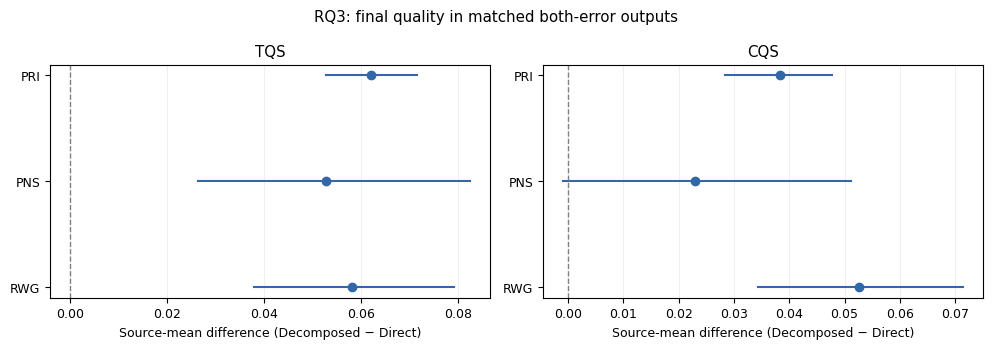

In [13]:
rq3_quality=comparisons(paired,["TQS","CQS"],family="RQ3_final_quality")
show_table("rq3_matched_final_quality",rq3_quality)
delta_plot(rq3_quality,["TQS","CQS"],"rq3_matched_final_quality","RQ3: final quality in matched both-error outputs")

### 6.2 Audited post-detection intervention and efficiency

,task,model_label,instance_id,generation_temperature_unified,run_id,config,post_detection_intervention_sec,hdm_intervention_total_sec,repair_attempted_cost,time_audit
0,Public Narrative Synthesis,Gemma3,7,0.0,1,Direct+HDM,26.818,45.996,1.0,valid
1,Public Narrative Synthesis,Gemma3,8,0.0,1,Direct+HDM,25.411,43.708,1.0,valid
2,Public Narrative Synthesis,Gemma3,10,0.0,1,Direct+HDM,32.398,60.390,1.0,valid
3,Public Narrative Synthesis,Gemma3,11,0.0,1,Direct+HDM,27.292,43.819,1.0,valid
4,Public Narrative Synthesis,Gemma3,12,0.0,1,Direct+HDM,31.654,54.486,1.0,valid
...,...,...,...,...,...,...,...,...,...,...
4142,Project Ideation,DeepSeek-R1,2534875,1.0,3,Decomposed+HDM,188.905,364.439,1.0,valid
4143,Project Ideation,DeepSeek-R1,2603392,1.0,3,Decomposed+HDM,240.884,391.891,1.0,valid
4144,Project Ideation,DeepSeek-R1,2525849,1.0,3,Decomposed+HDM,195.312,307.157,1.0,valid
4145,Project Ideation,DeepSeek-R1,2545538,1.0,3,Decomposed+HDM,246.650,379.758,1.0,valid


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,post_detection_intervention_sec,354,94,97.380110,187.500441,90.120331,83.082941,97.401362,0.00005,3.809732e-17,1.000000,91.380607,RQ3_cost,0.00045,True
1,Project Ideation,total_runtime_sec,354,94,227.497987,488.375707,260.877720,242.187386,279.774701,0.00005,6.163914e-17,0.993281,259.581740,RQ3_cost,0.00045,True
2,Project Ideation,net_detected_errors_reduced_per_minute,353,94,1.805997,0.732070,-1.073926,-1.416442,-0.744061,0.00005,2.417696e-08,-0.662710,-1.175717,RQ3_cost,0.00045,True
3,Public Narrative Synthesis,post_detection_intervention_sec,201,42,83.795680,125.665946,41.870266,19.305006,73.536036,0.00010,2.081130e-05,0.712071,35.537100,RQ3_cost,0.00045,True
4,Public Narrative Synthesis,total_runtime_sec,201,42,216.638775,342.024234,125.385459,64.673459,186.310190,0.00005,1.997232e-07,0.836102,128.428000,RQ3_cost,0.00045,True
5,Public Narrative Synthesis,net_detected_errors_reduced_per_minute,199,41,1.176125,0.621337,-0.554788,-1.120611,-0.019571,0.06070,1.786304e-02,-0.421603,-0.983821,RQ3_cost,0.06070,False
6,Related Work,post_detection_intervention_sec,115,58,66.636743,91.318519,24.681775,11.336738,44.937724,0.00005,2.405899e-05,0.637639,24.760330,RQ3_cost,0.00045,True
7,Related Work,total_runtime_sec,115,58,162.305189,291.981629,129.676441,103.486770,158.388927,0.00005,1.412531e-10,0.968440,123.433304,RQ3_cost,0.00045,True
8,Related Work,net_detected_errors_reduced_per_minute,115,58,1.601415,0.668608,-0.932806,-1.529179,-0.396982,0.00080,1.047685e-03,-0.499093,-0.796187,RQ3_cost,0.00160,True


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,repairability_count,354,94,0.375107,0.522466,0.147359,-0.112333,0.384621,0.25935,1.242544e-02,0.312175,0.188694,RQ1_primary_effectiveness,1.00000,False
1,Project Ideation,complete_repair,354,94,0.499774,0.669134,0.169360,0.067586,0.270422,0.00185,1.285476e-03,0.461538,0.152542,RQ1_primary_effectiveness,0.01110,True
2,Public Narrative Synthesis,repairability_count,201,42,0.451670,0.499353,0.047683,-0.180242,0.279743,0.68330,6.713303e-01,0.081081,-0.008217,RQ1_primary_effectiveness,1.00000,False
3,Public Narrative Synthesis,complete_repair,201,42,0.477563,0.584576,0.107012,-0.043113,0.250941,0.17540,1.731519e-01,0.304843,0.139303,RQ1_primary_effectiveness,0.87700,False
4,Related Work,repairability_count,115,58,0.667481,0.652545,-0.014936,-0.188452,0.142345,0.86205,8.998230e-01,-0.027094,-0.040580,RQ1_primary_effectiveness,1.00000,False
5,Related Work,complete_repair,115,58,0.678448,0.748112,0.069663,-0.069872,0.205427,0.33255,3.426141e-01,0.207977,0.060870,RQ1_primary_effectiveness,1.00000,False
6,Project Ideation,TQS,354,94,0.866258,0.928224,0.061966,0.052681,0.071378,0.00005,2.993399e-15,0.942347,0.061299,RQ3_final_quality,0.00030,True
7,Project Ideation,CQS,354,94,0.874996,0.913253,0.038257,0.028400,0.047771,0.00005,1.036334e-10,0.767525,0.037382,RQ3_final_quality,0.00030,True
8,Public Narrative Synthesis,TQS,201,42,0.838258,0.891068,0.052810,0.026285,0.082344,0.00015,5.534134e-04,0.619048,0.088536,RQ3_final_quality,0.00030,True
9,Public Narrative Synthesis,CQS,201,42,0.868136,0.891089,0.022953,-0.000861,0.051066,0.09865,2.112744e-01,0.226829,0.043350,RQ3_final_quality,0.09865,False


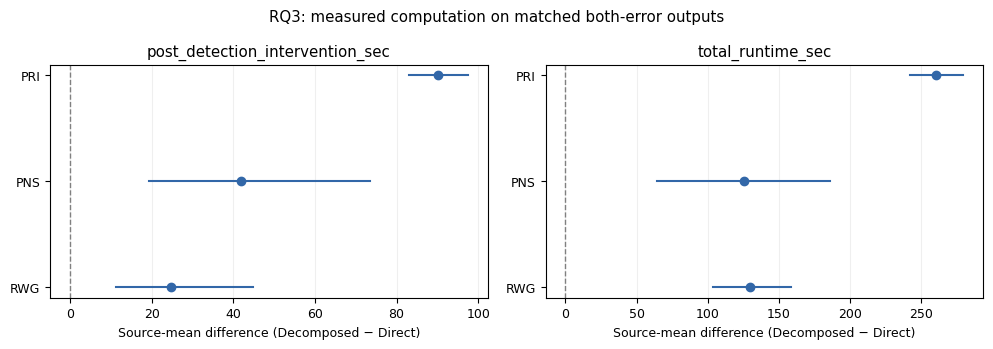

,task,config,comparable_attempted_rows,aggregate_net_detected_errors_reduced_per_minute
0,Project Ideation,Direct+HDM,353,1.844477
1,Project Ideation,Decomposed+HDM,353,0.732649
2,Public Narrative Synthesis,Direct+HDM,199,1.224677
3,Public Narrative Synthesis,Decomposed+HDM,199,0.476629
4,Related Work,Direct+HDM,115,1.052056
5,Related Work,Decomposed+HDM,115,0.558219


In [14]:
cost_rows=[]
for _,row in eligible.iterrows():
    if row.config=="Direct+HDM":
        revision,post=finite_number(row.get("revision_elapsed_sec")),finite_number(row.get("hdm_after_elapsed_sec"))
        time=revision+post if np.isfinite(revision) and np.isfinite(post) and revision>=0 and post>=0 else np.nan
        attempt=strict_bool(row.get("hdm_revision_performed"))
        if attempt is None:attempt=strict_bool(row.get("revision_performed"))
        # With this executed policy, positive valid revision duration establishes an attempt when no flag is stored.
        if attempt is None:attempt=True if np.isfinite(revision) and revision>0 else None
    else:
        time=finite_number(row.get("repair_elapsed_sec"));time=time if time>=0 else np.nan
        report=parse_json(row.get("repair_report_json"),dict) or {}
        attempt=strict_bool(row.get("repair_performed"))
        if attempt is None:attempt=strict_bool(report.get("repair_performed"))
    before=finite_number(row.get("hdm_before_elapsed_sec"))
    full=before+time if np.isfinite(before) and before>=0 and np.isfinite(time) else np.nan
    efficiency=row.wrong_claim_reduction/(time/60) if attempt is True and np.isfinite(time) and time>0 else np.nan
    cost_rows.append({"record_id":row.record_id,"post_detection_intervention_sec":time,"hdm_intervention_total_sec":full,
                      "repair_attempted_cost":float(attempt) if attempt is not None else np.nan,
                      "net_detected_errors_reduced_per_minute":efficiency,
                      "time_audit":"valid" if np.isfinite(time) else "missing_or_invalid_duration"})
cost=pd.DataFrame(cost_rows,columns=["record_id","post_detection_intervention_sec","hdm_intervention_total_sec","repair_attempted_cost","net_detected_errors_reduced_per_minute","time_audit"])
eligible=eligible.merge(cost,on="record_id",validate="one_to_one")
show_table("rq3_duration_audit",eligible[MATCH_KEYS+["config","post_detection_intervention_sec","hdm_intervention_total_sec","repair_attempted_cost","time_audit"]])
ALL_MATCHED_METRICS=RECOVERY_METRICS+["post_detection_intervention_sec","hdm_intervention_total_sec","net_detected_errors_reduced_per_minute"]
rq3_pairs=match_frames(eligible[eligible.config.eq("Direct+HDM")],eligible[eligible.config.eq("Decomposed+HDM")],ALL_MATCHED_METRICS)
assert len(rq3_pairs)==len(paired)
rq3_cost=comparisons(rq3_pairs,["post_detection_intervention_sec","total_runtime_sec","net_detected_errors_reduced_per_minute"],family="RQ3_cost")
show_table("rq3_matched_cost",rq3_cost)
tradeoff=pd.concat([rq1_primary,rq3_quality,rq3_cost],ignore_index=True)
show_table("rq3_tradeoff_source_weighted",tradeoff)
delta_plot(rq3_cost,["post_detection_intervention_sec","total_runtime_sec"],"rq3_cost_difference","RQ3: measured computation on matched both-error outputs")
throughput=[]
for task,g in rq3_pairs.groupby("task"):
    # Keep identical rows for the two policies; require actual measurable efficiency for both.
    mask=g.net_detected_errors_reduced_per_minute_direct.notna()&g.net_detected_errors_reduced_per_minute_decomp.notna()
    x=g[mask]
    for suffix,policy in [("direct","Direct+HDM"),("decomp","Decomposed+HDM")]:
        total_time=x[f"post_detection_intervention_sec_{suffix}"].sum()
        throughput.append({"task":task,"config":policy,"comparable_attempted_rows":len(x),"aggregate_net_detected_errors_reduced_per_minute":x[f"wrong_claim_reduction_{suffix}"].sum()/(total_time/60) if total_time>0 else np.nan})
show_table("rq3_aggregate_throughput_supplement",pd.DataFrame(throughput))

### 6.3 HDM configurations versus independently generated non-HDM baselines

,task,architecture,baseline_rows,hdm_population_rows,matched_rows,unmatched_baseline_rows,unmatched_hdm_rows
0,Public Narrative Synthesis,Direct,1412,588,572,840,16
1,Project Ideation,Direct,2575,1485,1455,1120,30
2,Related Work,Direct,2662,769,763,1899,6
3,Public Narrative Synthesis,Decomposed,1476,335,331,1145,4
4,Project Ideation,Decomposed,2673,587,583,2090,4
5,Related Work,Decomposed,2678,383,378,2300,5


,task,architecture,baseline_rows,hdm_population_rows,matched_rows,unmatched_baseline_rows,unmatched_hdm_rows
0,Public Narrative Synthesis,Direct,1412,1407,1372,40,35
1,Project Ideation,Direct,2575,2649,2542,33,107
2,Related Work,Direct,2662,2684,2647,15,37
3,Public Narrative Synthesis,Decomposed,1476,1460,1453,23,7
4,Project Ideation,Decomposed,2673,2631,2612,61,19
5,Related Work,Decomposed,2678,2655,2640,38,15


,task,architecture,metric,paired_rows,sources,Baseline,HDM,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,Decomposed,TQS,583,100,0.925167,0.927895,0.002727,0.000773,0.004792,0.00925,1.068432e-01,0.186667,0.002894,RQ3_eligible_baseline_quality,0.06265,False
1,Project Ideation,Decomposed,CQS,583,100,0.912870,0.916171,0.003301,0.000980,0.005769,0.00895,2.620804e-02,0.269841,0.003139,RQ3_eligible_baseline_quality,0.06265,False
2,Project Ideation,Direct,TQS,1455,100,0.897546,0.887222,-0.010324,-0.014693,-0.005961,0.00010,1.818542e-05,-0.496162,-0.011409,RQ3_eligible_baseline_quality,0.00090,True
3,Project Ideation,Direct,CQS,1454,100,0.902469,0.888440,-0.014029,-0.019003,-0.008920,0.00005,2.471037e-06,-0.542574,-0.014741,RQ3_eligible_baseline_quality,0.00060,True
4,Public Narrative Synthesis,Decomposed,TQS,331,51,0.892555,0.894575,0.002020,-0.006545,0.010845,0.65325,7.832203e-01,0.044706,0.003751,RQ3_eligible_baseline_quality,1.00000,False
5,Public Narrative Synthesis,Decomposed,CQS,331,51,0.892220,0.893676,0.001455,-0.004693,0.007503,0.63750,6.740184e-01,0.071230,-0.001289,RQ3_eligible_baseline_quality,1.00000,False
6,Public Narrative Synthesis,Direct,TQS,572,55,0.882564,0.865015,-0.017549,-0.027839,-0.008659,0.00020,3.579889e-04,-0.553247,-0.019543,RQ3_eligible_baseline_quality,0.00160,True
7,Public Narrative Synthesis,Direct,CQS,572,55,0.896109,0.886283,-0.009825,-0.018521,-0.001617,0.02980,6.407478e-02,-0.287013,-0.016999,RQ3_eligible_baseline_quality,0.14900,False
8,Related Work,Decomposed,TQS,378,92,0.926811,0.926834,0.000023,-0.007920,0.008058,0.99575,9.807390e-01,0.002930,-0.001194,RQ3_eligible_baseline_quality,1.00000,False
9,Related Work,Decomposed,CQS,378,92,0.920497,0.925091,0.004594,-0.002590,0.011998,0.22680,5.382491e-01,0.074295,0.003457,RQ3_eligible_baseline_quality,0.90720,False


,task,architecture,metric,paired_rows,sources,Baseline,HDM,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,Decomposed,TQS,2612,100,0.940589,0.941623,0.001035,0.000151,0.001970,0.03485,0.147266,0.166931,0.001035,RQ3_full_baseline_quality,0.24395,False
1,Project Ideation,Decomposed,CQS,2612,100,0.930046,0.931774,0.001728,0.000527,0.002976,0.00730,0.019926,0.268119,0.001734,RQ3_full_baseline_quality,0.07300,False
2,Project Ideation,Direct,TQS,2542,100,0.886042,0.882187,-0.003855,-0.006810,-0.000763,0.01630,0.013560,-0.284356,-0.003698,RQ3_full_baseline_quality,0.13040,False
3,Project Ideation,Direct,CQS,2541,100,0.891980,0.884295,-0.007685,-0.011375,-0.003988,0.00015,0.000327,-0.413861,-0.007721,RQ3_full_baseline_quality,0.00165,True
4,Public Narrative Synthesis,Decomposed,TQS,1453,55,0.901119,0.903293,0.002174,-0.001866,0.006380,0.30705,0.376728,0.137013,0.001927,RQ3_full_baseline_quality,0.66980,False
5,Public Narrative Synthesis,Decomposed,CQS,1453,55,0.898251,0.900544,0.002293,-0.000885,0.005616,0.16745,0.239119,0.182468,0.002212,RQ3_full_baseline_quality,0.66980,False
6,Public Narrative Synthesis,Direct,TQS,1372,55,0.889586,0.881495,-0.008091,-0.014507,-0.002189,0.01015,0.001585,-0.489610,-0.008386,RQ3_full_baseline_quality,0.09135,False
7,Public Narrative Synthesis,Direct,CQS,1372,55,0.907558,0.903611,-0.003947,-0.009962,0.001581,0.18380,0.298833,-0.161039,-0.004645,RQ3_full_baseline_quality,0.66980,False
8,Related Work,Decomposed,TQS,2640,100,0.923858,0.924546,0.000688,-0.002124,0.003532,0.62190,0.591697,0.061782,0.000693,RQ3_full_baseline_quality,0.66980,False
9,Related Work,Decomposed,CQS,2640,100,0.920032,0.922235,0.002202,-0.000586,0.004875,0.12075,0.157611,0.162772,0.002163,RQ3_full_baseline_quality,0.60375,False


,task,architecture,metric,paired_rows,sources,Baseline,HDM,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,Decomposed,total_runtime_sec,583,100,155.511823,440.708978,285.197155,273.752147,296.397872,0.00005,3.896560e-18,1.0,286.398595,RQ3_eligible_runtime_overhead,0.0003,True
1,Project Ideation,Direct,total_runtime_sec,1455,100,45.757192,196.894260,151.137068,143.650060,159.918106,0.00005,3.896560e-18,1.0,150.450948,RQ3_eligible_runtime_overhead,0.0003,True
2,Public Narrative Synthesis,Decomposed,total_runtime_sec,331,51,132.649431,362.472906,229.823474,193.039947,271.340101,0.00005,5.145276e-10,1.0,232.438495,RQ3_eligible_runtime_overhead,0.0003,True
3,Public Narrative Synthesis,Direct,total_runtime_sec,572,55,47.670488,201.457877,153.787389,132.888027,178.296565,0.00005,1.107615e-10,1.0,147.821414,RQ3_eligible_runtime_overhead,0.0003,True
4,Related Work,Decomposed,total_runtime_sec,378,92,161.449584,302.099716,140.650132,129.649187,151.606152,0.00005,8.149782e-17,1.0,142.773828,RQ3_eligible_runtime_overhead,0.0003,True
5,Related Work,Direct,total_runtime_sec,763,100,39.962782,159.390728,119.427946,112.823287,125.926946,0.00005,3.896560e-18,1.0,118.962105,RQ3_eligible_runtime_overhead,0.0003,True


,task,architecture,metric,paired_rows,sources,Baseline,HDM,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,Decomposed,total_runtime_sec,2612,100,115.969940,247.676483,131.706543,125.634365,137.795032,0.00005,3.896560e-18,1.000000,131.358351,RQ3_full_runtime_overhead,0.0003,True
1,Project Ideation,Direct,total_runtime_sec,2542,100,38.931117,145.356950,106.425834,101.736674,111.718273,0.00005,3.896560e-18,1.000000,106.123292,RQ3_full_runtime_overhead,0.0003,True
2,Public Narrative Synthesis,Decomposed,total_runtime_sec,1453,55,131.995796,250.501210,118.505414,106.100290,132.695527,0.00005,1.107615e-10,1.000000,118.033470,RQ3_full_runtime_overhead,0.0003,True
3,Public Narrative Synthesis,Direct,total_runtime_sec,1372,55,60.403954,167.143119,106.739166,96.788391,117.836702,0.00005,1.107615e-10,1.000000,106.161019,RQ3_full_runtime_overhead,0.0003,True
4,Related Work,Decomposed,total_runtime_sec,2640,100,147.828889,204.536580,56.707690,48.462913,62.886489,0.00005,7.559735e-17,0.960396,56.399615,RQ3_full_runtime_overhead,0.0003,True
5,Related Work,Direct,total_runtime_sec,2647,100,38.920764,107.239385,68.318621,65.633412,71.072739,0.00005,3.896560e-18,1.000000,68.220737,RQ3_full_runtime_overhead,0.0003,True


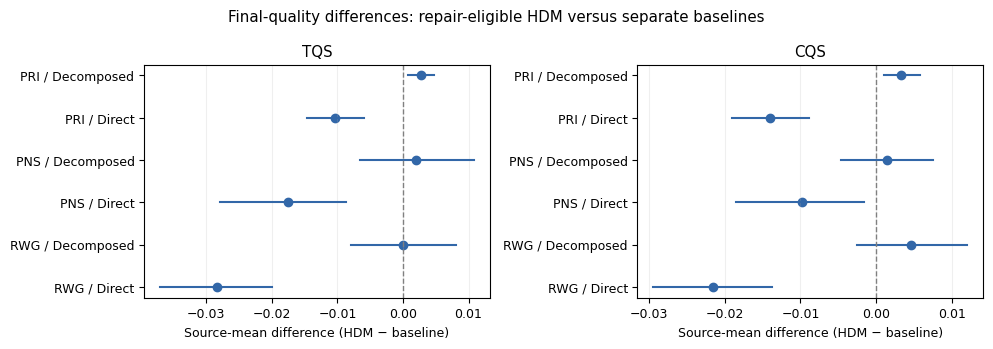

In [15]:
def baseline_pairs(hdm_population):
    result=[]; counts=[]
    for architecture,basecfg,hdmcfg in [("Direct","Direct","Direct+HDM"),("Decomposed","Decomposed","Decomposed+HDM")]:
        base=all_df[all_df.config.eq(basecfg)]
        hdm=hdm_population[hdm_population.config.eq(hdmcfg)]
        p=match_frames(base,hdm,["TQS","CQS","total_runtime_sec"])
        p["architecture"]=architecture
        result.append(p)
        for task in TASK_ORDER:
            ng=int(p.task.eq(task).sum());nb=int(base.task.eq(task).sum());nh=int(hdm.task.eq(task).sum())
            counts.append({"task":task,"architecture":architecture,"baseline_rows":nb,"hdm_population_rows":nh,"matched_rows":ng,"unmatched_baseline_rows":nb-ng,"unmatched_hdm_rows":nh-ng})
    return pd.concat(result,ignore_index=True),pd.DataFrame(counts)

hdm_baseline_eligible,eligible_baseline_counts=baseline_pairs(eligible)
hdm_baseline_full,full_baseline_counts=baseline_pairs(all_df[all_df.config.isin(WORKFLOW_ORDER)])
show_table("rq3_hdm_baseline_eligible_matching",eligible_baseline_counts)
show_table("rq3_hdm_baseline_full_matching",full_baseline_counts)
quality_change=comparisons(hdm_baseline_eligible,["TQS","CQS"],groups=("task","architecture"),family="RQ3_eligible_baseline_quality")
full_quality_change=comparisons(hdm_baseline_full,["TQS","CQS"],groups=("task","architecture"),family="RQ3_full_baseline_quality")
runtime_overhead=comparisons(hdm_baseline_eligible,["total_runtime_sec"],groups=("task","architecture"),family="RQ3_eligible_runtime_overhead")
full_runtime_overhead=comparisons(hdm_baseline_full,["total_runtime_sec"],groups=("task","architecture"),family="RQ3_full_runtime_overhead")
# Shared paired helper calls sides Direct/Decomposed; relabel them for this comparison.
for t in [quality_change,full_quality_change,runtime_overhead,full_runtime_overhead]:
    t.rename(columns={"Direct":"Baseline","Decomposed":"HDM"},inplace=True)
show_table("rq3_quality_difference_eligible_hdm_baseline",quality_change)
show_table("rq3_quality_difference_full_hdm_baseline",full_quality_change)
show_table("rq3_runtime_overhead_eligible",runtime_overhead)
show_table("rq3_runtime_overhead_full",full_runtime_overhead)
delta_plot(quality_change,["TQS","CQS"],"rq3_quality_change","Final-quality differences: repair-eligible HDM versus separate baselines",group_col="architecture")

### 6.4 Secondary milestone audit and requirement coverage

In [16]:
def audit_milestones(row):
    out={"record_id":row.record_id,"milestone_valid":False,"milestone_reason":"missing_full_expected_or_judge_json","priority_mismatches":0,"scalar_corrections":"","MAR":np.nan,"Mandatory MAR":np.nan,"Optional MAR":np.nan,"NPCS":np.nan}
    expected=parse_json(row.get("final_expected_milestones_json"),list)
    judge=parse_json(row.get("judge_output_json"),dict)
    scores=judge.get("milestone_judgment",{}).get("milestone_scores") if isinstance(judge,dict) and isinstance(judge.get("milestone_judgment"),dict) else None
    if not isinstance(expected,list) or not expected or not isinstance(scores,list):return out
    def get_ids(items):
        if not all(isinstance(x,dict) and x.get("milestone_id") is not None and str(x["milestone_id"]).strip() for x in items):return None
        return [str(x["milestone_id"]).strip() for x in items]
    eid,sid=get_ids(expected),get_ids(scores)
    if eid is None or sid is None or len(eid)!=len(set(eid)) or len(sid)!=len(set(sid)) or set(eid)!=set(sid):
        out["milestone_reason"]="duplicate_missing_or_unexpected_milestone_ids";return out
    emap={i:x for i,x in zip(eid,expected)}
    priority={i:str(x.get("priority","")).strip().upper() for i,x in emap.items()}
    if not set(priority.values()).issubset({"MANDATORY","OPTIONAL"}):
        out["milestone_reason"]="invalid_expected_priority";return out
    achieved={}; credit={}
    for i,x in zip(sid,scores):
        flag=strict_bool(x.get("achieved"));v=finite_number(x.get("score_1_to_5"))
        if flag is None or not np.isfinite(v) or not 1<=v<=5 or v!=int(v):
            out["milestone_reason"]="invalid_achieved_or_partial_credit";return out
        achieved[i]=int(flag);credit[i]=v
        out["priority_mismatches"]+=int(str(x.get("priority","")).strip().upper()!=priority[i])
    out["MAR"]=sum(achieved.values())/len(eid)
    for category,name in [("MANDATORY","Mandatory MAR"),("OPTIONAL","Optional MAR")]:
        ids=[i for i in eid if priority[i]==category]
        out[name]=sum(achieved[i] for i in ids)/len(ids) if ids else np.nan
    out["NPCS"]=sum(credit.values())/(5*len(eid))
    corrections=[]
    for metric,scalar in [("MAR","milestone_achievement_rate"),("Mandatory MAR","mandatory_milestone_achievement_rate"),("Optional MAR","optional_milestone_achievement_rate"),("NPCS","total_milestone_score_normalized")]:
        old=finite_number(row.get(scalar));new=out[metric]
        if (np.isfinite(old)!=np.isfinite(new)) or (np.isfinite(old) and not np.isclose(old,new,atol=1e-8)):corrections.append(scalar)
    out.update(milestone_valid=True,milestone_reason="valid",scalar_corrections=";".join(corrections))
    return out

milestone_audit=pd.DataFrame([audit_milestones(row) for _,row in all_df.iterrows()])
show_table("milestone_audit",milestone_audit.merge(all_df[["record_id"]+MATCH_KEYS+["config"]],on="record_id",validate="one_to_one"))
show_table("milestone_audit_summary",milestone_audit.groupby(["milestone_valid","milestone_reason"],as_index=False).size())
ms=all_df[["record_id"]+MATCH_KEYS+["config"]].merge(milestone_audit,on="record_id",validate="one_to_one")
# Same both-error condition keys as RQ1/RQ3; require valid scores for both sides metric by metric.
keys=paired[MATCH_KEYS].drop_duplicates()
ms=ms.merge(keys,on=MATCH_KEYS,how="inner",validate="many_to_one")
ms_pairs=match_frames(ms[ms.config.eq("Direct+HDM")],ms[ms.config.eq("Decomposed+HDM")],["MAR","Mandatory MAR","Optional MAR","NPCS"])
ms_results=comparisons(ms_pairs,["MAR","Mandatory MAR","Optional MAR","NPCS"],family="RQ3_secondary_milestones")
show_table("rq3_validated_milestone_comparison",ms_results)
show_table("rq3_milestone_population_validity",ms.groupby(["task","config","milestone_valid","milestone_reason"],as_index=False).size())

,record_id,milestone_valid,milestone_reason,priority_mismatches,scalar_corrections,MAR,Mandatory MAR,Optional MAR,NPCS,task,model_label,instance_id,generation_temperature_unified,run_id,config
0,0,True,valid,0,,0.750000,1.0,0.5,0.850000,Public Narrative Synthesis,Gemma3,3,0.0,1,Direct
1,1,True,valid,0,,0.750000,1.0,0.5,0.800000,Public Narrative Synthesis,Gemma3,5,0.0,1,Direct
2,2,True,valid,0,,0.750000,1.0,0.5,0.800000,Public Narrative Synthesis,Gemma3,6,0.0,1,Direct
3,3,True,valid,0,,0.750000,1.0,0.5,0.850000,Public Narrative Synthesis,Gemma3,7,0.0,1,Direct
4,4,True,valid,0,,1.000000,1.0,1.0,0.900000,Public Narrative Synthesis,Gemma3,8,0.0,1,Direct
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26957,26957,True,valid,0,,1.000000,1.0,1.0,0.800000,Project Ideation,DeepSeek-R1,2603392,1.0,3,Decomposed+HDM
26958,26958,True,valid,0,,0.666667,1.0,0.0,0.733333,Project Ideation,DeepSeek-R1,2525849,1.0,3,Decomposed+HDM
26959,26959,True,valid,0,,0.800000,1.0,0.5,0.760000,Project Ideation,DeepSeek-R1,2545538,1.0,3,Decomposed+HDM
26960,26960,False,duplicate_missing_or_unexpected_milestone_ids,0,,NaN,NaN,NaN,NaN,Project Ideation,DeepSeek-R1,2531941,1.0,3,Decomposed+HDM


,milestone_valid,milestone_reason,size
0,False,duplicate_missing_or_unexpected_milestone_ids,891
1,True,valid,26071


,task,metric,paired_rows,sources,Direct,Decomposed,delta,ci95_low,ci95_high,p_mean,p_signed_rank_sensitivity,rank_biserial_sensitivity,run_weighted_delta,family,p_holm,reject_holm
0,Project Ideation,MAR,313,92,0.578237,0.874940,0.296703,0.249894,0.342725,0.00005,1.107486e-14,0.937729,0.275278,RQ3_secondary_milestones,0.00060,True
1,Project Ideation,Mandatory MAR,313,92,0.835138,0.988009,0.152871,0.103959,0.206362,0.00005,1.309342e-07,0.883865,0.143024,RQ3_secondary_milestones,0.00060,True
2,Project Ideation,Optional MAR,312,92,0.335550,0.568728,0.233178,0.137623,0.329583,0.00005,1.119723e-05,0.602817,0.204060,RQ3_secondary_milestones,0.00060,True
3,Project Ideation,NPCS,313,92,0.662684,0.833406,0.170722,0.144343,0.196490,0.00005,7.260636e-15,0.944322,0.165725,RQ3_secondary_milestones,0.00060,True
4,Public Narrative Synthesis,MAR,181,40,0.788365,0.729221,-0.059145,-0.127959,0.012782,0.10270,5.627448e-02,-0.359886,0.033452,RQ3_secondary_milestones,0.41080,False
5,Public Narrative Synthesis,Mandatory MAR,181,40,0.896222,0.927707,0.031485,-0.024835,0.090416,0.32225,4.015344e-01,0.263736,0.119705,RQ3_secondary_milestones,0.73620,False
6,Public Narrative Synthesis,Optional MAR,177,40,0.689807,0.365607,-0.324200,-0.463491,-0.181021,0.00025,2.866648e-04,-0.710924,-0.212335,RQ3_secondary_milestones,0.00200,True
7,Public Narrative Synthesis,NPCS,181,40,0.786966,0.772172,-0.014794,-0.056648,0.031559,0.52375,1.116171e-01,-0.292308,0.046999,RQ3_secondary_milestones,0.73620,False
8,Related Work,MAR,112,56,0.836639,0.870789,0.034150,-0.019607,0.089496,0.24540,3.211328e-01,0.183536,0.024926,RQ3_secondary_milestones,0.73620,False
9,Related Work,Mandatory MAR,112,56,0.930697,0.979464,0.048767,0.005313,0.099710,0.04275,6.085442e-02,0.636364,0.033482,RQ3_secondary_milestones,0.25650,False


,task,config,milestone_valid,milestone_reason,size
0,Project Ideation,Decomposed,False,duplicate_missing_or_unexpected_milestone_ids,20
1,Project Ideation,Decomposed,True,valid,334
2,Project Ideation,Decomposed+HDM,False,duplicate_missing_or_unexpected_milestone_ids,41
3,Project Ideation,Decomposed+HDM,True,valid,313
4,Project Ideation,Direct,False,duplicate_missing_or_unexpected_milestone_ids,3
5,Project Ideation,Direct,True,valid,350
6,Project Ideation,Direct+HDM,True,valid,354
7,Public Narrative Synthesis,Decomposed,False,duplicate_missing_or_unexpected_milestone_ids,17
8,Public Narrative Synthesis,Decomposed,True,valid,180
9,Public Narrative Synthesis,Decomposed+HDM,False,duplicate_missing_or_unexpected_milestone_ids,16


## 7. Results summary

In [17]:
texts=[]
for table,label in [(rq1_primary,"RQ1 matched effectiveness"),(rq3_quality,"RQ3 final quality"),(rq3_cost,"RQ3 cost")]:
    for row in table.itertuples():
        if not np.isfinite(row.delta):
            texts.append(f"{label}, {TASK_SHORT[row.task]}, {row.metric}: no valid paired estimate.");continue
        direction="higher" if row.delta>0 else "lower" if row.delta<0 else "equal"
        evidence="rejected the null after Holm correction" if row.reject_holm else "did not reject the null after Holm correction"
        p=f"{row.p_holm:.4g}" if np.isfinite(row.p_holm) else "not available"
        texts.append(f"{label}, {TASK_SHORT[row.task]}, {row.metric}: Decomposed is {direction}; source-mean delta {row.delta:.3f}, pointwise 95% CI [{row.ci95_low:.3f}, {row.ci95_high:.3f}], {row.sources} sources / {row.paired_rows} paired rows; mean test {evidence} (p_Holm={p}).")
display(Markdown("\n\n".join(texts)))
print("Interpret all baseline deltas as final configuration differences, not preservation.")
print("RQ2 route contrasts are descriptive and have no causal interpretation.")
print("Claims of significance are based on p_holm, not merely the direction or the unadjusted interval.")

RQ1 matched effectiveness, PRI, repairability_count: Decomposed is higher; source-mean delta 0.147, pointwise 95% CI [-0.112, 0.385], 94 sources / 354 paired rows; mean test did not reject the null after Holm correction (p_Holm=1).

RQ1 matched effectiveness, PRI, complete_repair: Decomposed is higher; source-mean delta 0.169, pointwise 95% CI [0.068, 0.270], 94 sources / 354 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0111).

RQ1 matched effectiveness, PNS, repairability_count: Decomposed is higher; source-mean delta 0.048, pointwise 95% CI [-0.180, 0.280], 42 sources / 201 paired rows; mean test did not reject the null after Holm correction (p_Holm=1).

RQ1 matched effectiveness, PNS, complete_repair: Decomposed is higher; source-mean delta 0.107, pointwise 95% CI [-0.043, 0.251], 42 sources / 201 paired rows; mean test did not reject the null after Holm correction (p_Holm=0.877).

RQ1 matched effectiveness, RWG, repairability_count: Decomposed is lower; source-mean delta -0.015, pointwise 95% CI [-0.188, 0.142], 58 sources / 115 paired rows; mean test did not reject the null after Holm correction (p_Holm=1).

RQ1 matched effectiveness, RWG, complete_repair: Decomposed is higher; source-mean delta 0.070, pointwise 95% CI [-0.070, 0.205], 58 sources / 115 paired rows; mean test did not reject the null after Holm correction (p_Holm=1).

RQ3 final quality, PRI, TQS: Decomposed is higher; source-mean delta 0.062, pointwise 95% CI [0.053, 0.071], 94 sources / 354 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0003).

RQ3 final quality, PRI, CQS: Decomposed is higher; source-mean delta 0.038, pointwise 95% CI [0.028, 0.048], 94 sources / 354 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0003).

RQ3 final quality, PNS, TQS: Decomposed is higher; source-mean delta 0.053, pointwise 95% CI [0.026, 0.082], 42 sources / 201 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0003).

RQ3 final quality, PNS, CQS: Decomposed is higher; source-mean delta 0.023, pointwise 95% CI [-0.001, 0.051], 42 sources / 201 paired rows; mean test did not reject the null after Holm correction (p_Holm=0.09865).

RQ3 final quality, RWG, TQS: Decomposed is higher; source-mean delta 0.058, pointwise 95% CI [0.038, 0.079], 58 sources / 115 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0003).

RQ3 final quality, RWG, CQS: Decomposed is higher; source-mean delta 0.053, pointwise 95% CI [0.034, 0.071], 58 sources / 115 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0003).

RQ3 cost, PRI, post_detection_intervention_sec: Decomposed is higher; source-mean delta 90.120, pointwise 95% CI [83.083, 97.401], 94 sources / 354 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, PRI, total_runtime_sec: Decomposed is higher; source-mean delta 260.878, pointwise 95% CI [242.187, 279.775], 94 sources / 354 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, PRI, net_detected_errors_reduced_per_minute: Decomposed is lower; source-mean delta -1.074, pointwise 95% CI [-1.416, -0.744], 94 sources / 353 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, PNS, post_detection_intervention_sec: Decomposed is higher; source-mean delta 41.870, pointwise 95% CI [19.305, 73.536], 42 sources / 201 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, PNS, total_runtime_sec: Decomposed is higher; source-mean delta 125.385, pointwise 95% CI [64.673, 186.310], 42 sources / 201 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, PNS, net_detected_errors_reduced_per_minute: Decomposed is lower; source-mean delta -0.555, pointwise 95% CI [-1.121, -0.020], 41 sources / 199 paired rows; mean test did not reject the null after Holm correction (p_Holm=0.0607).

RQ3 cost, RWG, post_detection_intervention_sec: Decomposed is higher; source-mean delta 24.682, pointwise 95% CI [11.337, 44.938], 58 sources / 115 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, RWG, total_runtime_sec: Decomposed is higher; source-mean delta 129.676, pointwise 95% CI [103.487, 158.389], 58 sources / 115 paired rows; mean test rejected the null after Holm correction (p_Holm=0.00045).

RQ3 cost, RWG, net_detected_errors_reduced_per_minute: Decomposed is lower; source-mean delta -0.933, pointwise 95% CI [-1.529, -0.397], 58 sources / 115 paired rows; mean test rejected the null after Holm correction (p_Holm=0.0016).

Interpret all baseline deltas as final configuration differences, not preservation.
RQ2 route contrasts are descriptive and have no causal interpretation.
Claims of significance are based on p_holm, not merely the direction or the unadjusted interval.


## 8. Verification assertions and execution record

In [ ]:
assert not all_df.duplicated(MATCH_KEYS+["config"]).any()
assert len(eligible)==sum(eligible.groupby("config").size())
assert np.allclose(eligible.repairability_count,1-eligible.wrong_after/eligible.wrong_before)
assert (eligible.repairability_count<=1).all()
assert eligible.complete_repair.isin([0.,1.]).all()
for col in ["TQS","CQS"]:assert all_df[col].dropna().between(0,1).all()
for col in ["MAR","Mandatory MAR","Optional MAR","NPCS"]:assert milestone_audit[col].dropna().between(0,1).all()
for t in [rq1_primary,rq3_quality,rq3_cost,ms_results]:
    good=t.dropna(subset=["Direct","Decomposed","delta"])
    assert np.allclose(good.delta,good.Decomposed-good.Direct)
    assert t.p_holm.dropna().between(0,1).all()
for figure in ["rq1_matched_summary","rq2_error_origin","rq3_matched_final_quality","rq3_cost_difference","rq3_quality_change"]:
    for ext in ["pdf","png"]:
        path=OUTPUT_DIR/f"{figure}.{ext}"
        assert path.is_file() and path.stat().st_size>1000, f"Missing or empty figure: {path}"
execution_record={"seed":RANDOM_SEED,"bootstrap_draws":N_BOOT,"signflip_draws":N_PERM,"planned_runs":planned_runs,"retained_rows":len(all_df),"valid_recovery_outputs":len(repair_df),"eligible_valid_recovery_outputs":len(eligible),"matched_both_error_pairs":len(paired),"primary_weighting":"equal source means within task","bootstrap":"source mean percentile","primary_test":"source mean sign-flip","pointwise_ci":True,"task_sizes":TASK_SIZES,"input_sha256":{str(spec["path"]):hashlib.sha256(Path(spec["path"]).read_bytes()).hexdigest() for spec in DATA_SPECS}}
(OUTPUT_DIR/"execution_record.json").write_text(json.dumps(execution_record,indent=2))
print("All structural and arithmetic checks passed.")
print("Tables:",len(TABLES),"; publication figures exported with their intended axes.")
